# ██ FLOW 1 · FOTO → CÓDIGO DITO → MÁSCARA LEGO ██
**UTEC · Proyecto 2 · semilla 42 · versión f1d_dito**

Libreta completa, adaptada desde tu Flow 1 f1c. **No contiene resultados de un nuevo entrenamiento LEGO.** Ejecutar de arriba abajo. Se conserva el DiT 6×256, atención cruzada y rectified flow; se corrigen integración, evaluación y reanudación.

## 0. Cambios y decisiones

* Carga `pares.csv` y `pares_syn.csv`; exige correspondencia de todas las filas aceptadas.
* Tokenizer **DiTo base congelado**, con el código y pesos exactos del experimento anterior. Recalcula códigos y espejos de TODOS los targets; no mezcla latentes antiguos. Este notebook **no admite directamente el checkpoint VAE original**.
* Todas las estadísticas de normalización se calculan en máscaras únicas de **train del flow**, después del split.
* Conserva splits originales. Aparta familias de intermedias para val/test del flow; los padres pueden seguir en train. Es una evaluación de combinaciones nuevas, distinta de padres totalmente nuevos.
* Muestreo por máscara y después foto; espejos conjuntos y aumentos suaves, configurables.
* Modelo `flow` por defecto; `regresor` es un control opcional que se ejecuta en otra carpeta con los mismos datos/splits. No incorpora CSFM o REPA sin una ablación: esta es la base corregida.
* Checkpoint por generación de validación, no por similitud al catálogo. Incluye retrieval, oráculo de train, techo del tokenizer, foto barajada, copia y métricas por máscara.
* `tqdm` en procesos medianos/largos; logs cada 100 actualizaciones. Checkpoints completos, huellas de datos/codec/condición y estados RNG.

La corrida anterior eligió DINOv2-base al fallar DINOv3. Lo fijamos sin fallback silencioso. El valor 0.7439 anterior fue **MSE de velocidad**; el Dice de prueba fue 0.533.

## 1. INPUTS QUE DEBES AÑADIR EN KAGGLE

| Input | Contenido necesario |
|---|---|
| PairLegoFace | `pares.csv` + fotos g1/g2, conservando las carpetas de cada parte |
| Personas intermedias | `pares_syn.csv` + las cinco carpetas `personas_int_personaN/imagenes/` |
| Dataset de intermedias LEGO | **`dataset.csv` y `dataset/tXXXXX.png` originales**. Los ZIP de personas no contienen estos PNG |
| LegosPartsVae | `caras_vae.parquet` y las estampas originales RGBA |
| Output del experimento DiTo | `lego_geometria/manifest.csv`, `runs/dito_base/best.pt`, `procedencia.json` si está disponible |
| Output de esta libreta | Opcional para reanudar; no agregar versiones duplicadas de los inputs anteriores |

GPU T4×2: flow en GPU 0 y DINO en GPU 1. Con una GPU también funciona usando lotes menores. Internet para instalar dependencias y descargar DINOv2. No requiere HF_TOKEN para ese modelo público. No se asume acceso a datos privados de Hugging Face.

Los buscadores fallan ante ambigüedad: fija las rutas de CONFIG. Si el dataset de estampas no usa `ruta`, fija `REAL_DIR`. Las máscaras se centran en 128×128 sin reescalar. Los PNG sin transparencia, cambios de partición, padres incompatibles o fotos faltantes detienen el preflight.

In [1]:
import sys, subprocess
subprocess.check_call([sys.executable,'-m','pip','install','-q',
 'transformers>=4.56,<5','accelerate','einops','pyarrow','opencv-python-headless>=4.10,<5','tqdm','matplotlib'])

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


0

In [2]:
import os, sys, json, math, time, random, copy, hashlib, io, glob, shutil, importlib.util
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from tqdm.auto import tqdm

CONFIG=dict(
 VERSION='f1d_dito', MODO='flow', SEMILLA=42, SMOKE=False,
 RAIZ='/kaggle/input', SALIDA='/kaggle/working/flow1_dito',
 PARES=None, PARES_SYN=None, CSV_INTER=None, PARQUET=None, REAL_DIR=None,
 CK_DITO=None, MANIFEST_DITO=None, REANUDAR_DE=None,
 DINO='facebook/dinov2-base', LADO_FOTO=224,
 DIM=256, PROFUNDIDAD=6, CABEZAS=4, MLP=4., DROPOUT=.1,
 PASOS=6000, LOTE=32, ACUMULAR=2, LR=3e-4, WEIGHT_DECAY=.1,
 WARMUP=300, LR_FINAL=.05, CLIP=1., EMA=.999, P_SIN_FOTO=.2,
 ESPEJO=True, AUMENTO=True, LOG_CADA=100, EVAL_MSE=500, EVAL_GEN=1000,
 GUARDAR_CADA=250, PACIENCIA=5, LIMITE_HORAS=10.5,
 FRAC_INTER_VAL=.10, FRAC_INTER_TEST=.10, FRAC_PERSONAS_INTER=.20,
 PASOS_FLOW=25, PASOS_DITO=16, PASOS_DITO_FINAL=32,
 LOTE_EVAL=8, N_VAL_GRUPO=8, CFG_PESOS=[1.,1.5,2.],
 CFG_CHECKPOINT=1., UMBRAL_COPIA=.995, SEMILLAS_TEST=[42,43],
 CHECK_SHA_FOTOS=True, SOBREAJUSTE=True, PASOS_SOBREAJUSTE=600,
)
if os.environ.get('FLOW_SMOKE')=='1':CONFIG['SMOKE']=True
if CONFIG['SMOKE']:
 CONFIG.update(DIM=32,PROFUNDIDAD=1,CABEZAS=2,PASOS=2,LOTE=2,ACUMULAR=1,
  WARMUP=1,EVAL_MSE=2,EVAL_GEN=2,GUARDAR_CADA=1,PASOS_FLOW=2,PASOS_DITO=2,
  PASOS_DITO_FINAL=2,N_VAL_GRUPO=1,CFG_PESOS=[1.],SEMILLAS_TEST=[42],
  PASOS_SOBREAJUSTE=2,LOG_CADA=100)
BASE_OUT=Path(CONFIG['SALIDA'])
RUN=BASE_OUT/(CONFIG['VERSION']+'_'+CONFIG['MODO']+('_smoke' if CONFIG['SMOKE'] else ''))
RUN.mkdir(parents=True,exist_ok=True)
DEVICE=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
DINO_DEVICE=torch.device('cuda:1' if torch.cuda.device_count()>1 else DEVICE)
AMP=DEVICE.type=='cuda'
def seed_all(s):
 random.seed(s);np.random.seed(s);torch.manual_seed(s)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(s)
seed_all(42)
torch.backends.cudnn.benchmark=False
if AMP:torch.backends.cuda.matmul.allow_tf32=True

def sha_file(p):
 h=hashlib.sha256()
 with open(p,'rb') as f:
  for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
 return h.hexdigest()
def unique(name,explicit=None):
 if explicit:
  p=Path(explicit);assert p.is_file(),p;return p
 hits=sorted(Path(CONFIG['RAIZ']).rglob(name))
 if len(hits)!=1:raise ValueError(f'{name}: {len(hits)} candidatos; fija ruta en CONFIG: {hits[:15]}')
 return hits[0]
def amp_ctx():return torch.autocast('cuda',dtype=torch.float16) if AMP else nullcontext()
print('Flow:',DEVICE,'DINO:',DINO_DEVICE,'modo:',CONFIG['MODO'])

Flow: cuda:0 DINO: cuda:0 modo: flow


## 2. Codec exacto y procedencia

Se incorporan los módulos oficiales DiTo del notebook anterior (commit `d2dc2993ffc627ebf2240d54a2afe153a59554a7`, Apache-2.0). Encoder y UNet pequeño coinciden con `dito_base`; salida de un canal. El alias antiguo `upsample_nearest` se reemplaza por `interpolate(mode="nearest")`, matemáticamente equivalente. No cambia la ecuación ni los pesos. La carga es estricta y verifica recodificación contra el NPZ si se proporciona después.

El encoder produce un código determinista normalizado por LayerNorm. El flow usa sus propias estadísticas por canal y el decoder recibe siempre el código desestandarizado. No se toman estadísticas del color ni de otro modelo.

In [3]:
UPSTREAM_TEXT = {'codec.py': '# pytorch_diffusion + derived encoder decoder\nimport math\nimport torch\nimport torch.nn as nn\nimport numpy as np\nfrom einops import rearrange\n\nfrom upstream_registry import register\n\n\nclass LinearAttention(nn.Module):\n    def __init__(self, dim, heads=4, dim_head=32):\n        super().__init__()\n        self.heads = heads\n        hidden_dim = dim_head * heads\n        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias = False)\n        self.to_out = nn.Conv2d(hidden_dim, dim, 1)\n\n    def forward(self, x):\n        b, c, h, w = x.shape\n        qkv = self.to_qkv(x)\n        q, k, v = rearrange(qkv, \'b (qkv heads c) h w -> qkv b heads c (h w)\', heads = self.heads, qkv=3)\n        k = k.softmax(dim=-1)\n        context = torch.einsum(\'bhdn,bhen->bhde\', k, v)\n        out = torch.einsum(\'bhde,bhdn->bhen\', context, q)\n        out = rearrange(out, \'b heads c (h w) -> b (heads c) h w\', heads=self.heads, h=h, w=w)\n        return self.to_out(out)\n\n\ndef get_timestep_embedding(timesteps, embedding_dim):\n    """\n    This matches the implementation in Denoising Diffusion Probabilistic Models:\n    From Fairseq.\n    Build sinusoidal embeddings.\n    This matches the implementation in tensor2tensor, but differs slightly\n    from the description in Section 3.5 of "Attention Is All You Need".\n    """\n    assert len(timesteps.shape) == 1\n\n    half_dim = embedding_dim // 2\n    emb = math.log(10000) / (half_dim - 1)\n    emb = torch.exp(torch.arange(half_dim, dtype=torch.float32) * -emb)\n    emb = emb.to(device=timesteps.device)\n    emb = timesteps.float()[:, None] * emb[None, :]\n    emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)\n    if embedding_dim % 2 == 1:  # zero pad\n        emb = torch.nn.functional.pad(emb, (0,1,0,0))\n    return emb\n\n\ndef nonlinearity(x):\n    # swish\n    return x*torch.sigmoid(x)\n\n\ndef Normalize(in_channels, num_groups=32):\n    return torch.nn.GroupNorm(num_groups=num_groups, num_channels=in_channels, eps=1e-6, affine=True)\n\n\nclass Upsample(nn.Module):\n    def __init__(self, in_channels, with_conv):\n        super().__init__()\n        self.with_conv = with_conv\n        if self.with_conv:\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        x = torch.nn.functional.interpolate(x, scale_factor=2.0, mode="nearest")\n        if self.with_conv:\n            x = self.conv(x)\n        return x\n\n\nclass Downsample(nn.Module):\n    def __init__(self, in_channels, with_conv):\n        super().__init__()\n        self.with_conv = with_conv\n        if self.with_conv:\n            # no asymmetric padding in torch conv, must do it ourselves\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=3,\n                                        stride=2,\n                                        padding=0)\n\n    def forward(self, x):\n        if self.with_conv:\n            pad = (0,1,0,1)\n            x = torch.nn.functional.pad(x, pad, mode="constant", value=0)\n            x = self.conv(x)\n        else:\n            x = torch.nn.functional.avg_pool2d(x, kernel_size=2, stride=2)\n        return x\n\n\nclass ResnetBlock(nn.Module):\n    def __init__(self, *, in_channels, out_channels=None, kernel_size=3, conv_shortcut=False,\n                 dropout, temb_channels=512, normalize=True):\n        super().__init__()\n        self.in_channels = in_channels\n        out_channels = in_channels if out_channels is None else out_channels\n        self.out_channels = out_channels\n        self.use_conv_shortcut = conv_shortcut\n\n        self.norm1 = Normalize(in_channels) if normalize else torch.nn.Identity()\n        self.conv1 = torch.nn.Conv2d(in_channels,\n                                     out_channels,\n                                     kernel_size=kernel_size,\n                                     stride=1,\n                                     padding=(kernel_size - 1) // 2)\n        if temb_channels > 0:\n            self.temb_proj = torch.nn.Linear(temb_channels,\n                                             out_channels)\n        self.norm2 = Normalize(out_channels) if normalize else torch.nn.Identity()\n        self.dropout = torch.nn.Dropout(dropout)\n        self.conv2 = torch.nn.Conv2d(out_channels,\n                                     out_channels,\n                                     kernel_size=kernel_size,\n                                     stride=1,\n                                     padding=(kernel_size - 1) // 2)\n        if self.in_channels != self.out_channels:\n            if self.use_conv_shortcut:\n                self.conv_shortcut = torch.nn.Conv2d(in_channels,\n                                                     out_channels,\n                                                     kernel_size=kernel_size,\n                                                     stride=1,\n                                                     padding=(kernel_size - 1) // 2)\n            else:\n                self.nin_shortcut = torch.nn.Conv2d(in_channels,\n                                                    out_channels,\n                                                    kernel_size=1,\n                                                    stride=1,\n                                                    padding=0)\n\n    def forward(self, x, temb):\n        h = x\n        h = self.norm1(h)\n        h = nonlinearity(h)\n        h = self.conv1(h)\n\n        if temb is not None:\n            h = h + self.temb_proj(nonlinearity(temb))[:,:,None,None]\n\n        h = self.norm2(h)\n        h = nonlinearity(h)\n        h = self.dropout(h)\n        h = self.conv2(h)\n\n        if self.in_channels != self.out_channels:\n            if self.use_conv_shortcut:\n                x = self.conv_shortcut(x)\n            else:\n                x = self.nin_shortcut(x)\n\n        return x+h\n\n\nclass LinAttnBlock(LinearAttention):\n    """to match AttnBlock usage"""\n    def __init__(self, in_channels):\n        super().__init__(dim=in_channels, heads=1, dim_head=in_channels)\n\n\nclass AttnBlock(nn.Module):\n    def __init__(self, in_channels):\n        super().__init__()\n        self.in_channels = in_channels\n\n        self.norm = Normalize(in_channels)\n        self.q = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.k = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.v = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.proj_out = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=1,\n                                        stride=1,\n                                        padding=0)\n\n\n    def forward(self, x):\n        h_ = x\n        h_ = self.norm(h_)\n        q = self.q(h_)\n        k = self.k(h_)\n        v = self.v(h_)\n\n        # compute attention\n        b,c,h,w = q.shape\n        q = q.reshape(b,c,h*w)\n        q = q.permute(0,2,1)   # b,hw,c\n        k = k.reshape(b,c,h*w) # b,c,hw\n        w_ = torch.bmm(q,k)     # b,hw,hw    w[b,i,j]=sum_c q[b,i,c]k[b,c,j]\n        w_ = w_ * (int(c)**(-0.5))\n        w_ = torch.nn.functional.softmax(w_, dim=2)\n\n        # attend to values\n        v = v.reshape(b,c,h*w)\n        w_ = w_.permute(0,2,1)   # b,hw,hw (first hw of k, second of q)\n        h_ = torch.bmm(v,w_)     # b, c,hw (hw of q) h_[b,c,j] = sum_i v[b,c,i] w_[b,i,j]\n        h_ = h_.reshape(b,c,h,w)\n\n        h_ = self.proj_out(h_)\n\n        return x+h_\n\n\ndef make_attn(in_channels, attn_type="vanilla"):\n    assert attn_type in ["vanilla", "linear", "none"], f\'attn_type {attn_type} unknown\'\n    # print(f"making attention of type \'{attn_type}\' with {in_channels} in_channels")\n    if attn_type == "vanilla":\n        return AttnBlock(in_channels)\n    elif attn_type == "none":\n        return nn.Identity(in_channels)\n    else:\n        return LinAttnBlock(in_channels)\n\n\nclass Model(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, use_timestep=True, use_linear_attn=False, attn_type="vanilla"):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = self.ch*4\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n\n        self.use_timestep = use_timestep\n        if self.use_timestep:\n            # timestep embedding\n            self.temb = nn.Module()\n            self.temb.dense = nn.ModuleList([\n                torch.nn.Linear(self.ch,\n                                self.temb_ch),\n                torch.nn.Linear(self.temb_ch,\n                                self.temb_ch),\n            ])\n\n        # downsampling\n        self.conv_in = torch.nn.Conv2d(in_channels,\n                                       self.ch,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        curr_res = resolution\n        in_ch_mult = (1,)+tuple(ch_mult)\n        self.down = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_in = ch*in_ch_mult[i_level]\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            down = nn.Module()\n            down.block = block\n            down.attn = attn\n            if i_level != self.num_resolutions-1:\n                down.downsample = Downsample(block_in, resamp_with_conv)\n                curr_res = curr_res // 2\n            self.down.append(down)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # upsampling\n        self.up = nn.ModuleList()\n        for i_level in reversed(range(self.num_resolutions)):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_out = ch*ch_mult[i_level]\n            skip_in = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks+1):\n                if i_block == self.num_res_blocks:\n                    skip_in = ch*in_ch_mult[i_level]\n                block.append(ResnetBlock(in_channels=block_in+skip_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            up = nn.Module()\n            up.block = block\n            up.attn = attn\n            if i_level != 0:\n                up.upsample = Upsample(block_in, resamp_with_conv)\n                curr_res = curr_res * 2\n            self.up.insert(0, up) # prepend to get consistent order\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        out_ch,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x, t=None, context=None):\n        #assert x.shape[2] == x.shape[3] == self.resolution\n        if context is not None:\n            # assume aligned context, cat along channel axis\n            x = torch.cat((x, context), dim=1)\n        if self.use_timestep:\n            # timestep embedding\n            assert t is not None\n            temb = get_timestep_embedding(t, self.ch)\n            temb = self.temb.dense[0](temb)\n            temb = nonlinearity(temb)\n            temb = self.temb.dense[1](temb)\n        else:\n            temb = None\n\n        # downsampling\n        hs = [self.conv_in(x)]\n        for i_level in range(self.num_resolutions):\n            for i_block in range(self.num_res_blocks):\n                h = self.down[i_level].block[i_block](hs[-1], temb)\n                if len(self.down[i_level].attn) > 0:\n                    h = self.down[i_level].attn[i_block](h)\n                hs.append(h)\n            if i_level != self.num_resolutions-1:\n                hs.append(self.down[i_level].downsample(hs[-1]))\n\n        # middle\n        h = hs[-1]\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # upsampling\n        for i_level in reversed(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks+1):\n                h = self.up[i_level].block[i_block](\n                    torch.cat([h, hs.pop()], dim=1), temb)\n                if len(self.up[i_level].attn) > 0:\n                    h = self.up[i_level].attn[i_block](h)\n            if i_level != 0:\n                h = self.up[i_level].upsample(h)\n\n        # end\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n    def get_last_layer(self):\n        return self.conv_out.weight\n\n\nclass Encoder(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, z_channels, double_z=True, use_linear_attn=False, attn_type="vanilla",\n                 **ignore_kwargs):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n\n        # downsampling\n        self.conv_in = torch.nn.Conv2d(in_channels,\n                                       self.ch,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        curr_res = resolution\n        in_ch_mult = (1,)+tuple(ch_mult)\n        self.in_ch_mult = in_ch_mult\n        self.down = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_in = ch*in_ch_mult[i_level]\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            down = nn.Module()\n            down.block = block\n            down.attn = attn\n            if i_level != self.num_resolutions-1:\n                down.downsample = Downsample(block_in, resamp_with_conv)\n                curr_res = curr_res // 2\n            self.down.append(down)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        2*z_channels if double_z else z_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        # timestep embedding\n        temb = None\n\n        # downsampling\n        hs = [self.conv_in(x)]\n        for i_level in range(self.num_resolutions):\n            for i_block in range(self.num_res_blocks):\n                h = self.down[i_level].block[i_block](hs[-1], temb)\n                if len(self.down[i_level].attn) > 0:\n                    h = self.down[i_level].attn[i_block](h)\n                hs.append(h)\n            if i_level != self.num_resolutions-1:\n                hs.append(self.down[i_level].downsample(hs[-1]))\n\n        # middle\n        h = hs[-1]\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # end\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n\nclass Decoder(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, z_channels, give_pre_end=False, tanh_out=False, use_linear_attn=False,\n                 attn_type="vanilla", **ignorekwargs):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n        self.give_pre_end = give_pre_end\n        self.tanh_out = tanh_out\n\n        # compute in_ch_mult, block_in and curr_res at lowest res\n        in_ch_mult = (1,)+tuple(ch_mult)\n        block_in = ch*ch_mult[self.num_resolutions-1]\n        curr_res = resolution // 2**(self.num_resolutions-1)\n        self.z_shape = (1,z_channels,curr_res,curr_res)\n        # print("Working with z of shape {} = {} dimensions.".format(\n        #     self.z_shape, np.prod(self.z_shape)))\n\n        # z to block_in\n        self.conv_in = torch.nn.Conv2d(z_channels,\n                                       block_in,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # upsampling\n        self.up = nn.ModuleList()\n        for i_level in reversed(range(self.num_resolutions)):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks+1):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            up = nn.Module()\n            up.block = block\n            up.attn = attn\n            if i_level != 0:\n                up.upsample = Upsample(block_in, resamp_with_conv)\n                curr_res = curr_res * 2\n            self.up.insert(0, up) # prepend to get consistent order\n\n        # end\n        if not self.give_pre_end:\n            self.norm_out = Normalize(block_in)\n            self.conv_out = torch.nn.Conv2d(block_in,\n                                            out_ch,\n                                            kernel_size=3,\n                                            stride=1,\n                                            padding=1)\n\n    def forward(self, z):\n        #assert z.shape[1:] == self.z_shape[1:]\n        self.last_z_shape = z.shape\n\n        # timestep embedding\n        temb = None\n\n        # z to block_in\n        h = self.conv_in(z)\n\n        # middle\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # upsampling\n        for i_level in reversed(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks+1):\n                h = self.up[i_level].block[i_block](h, temb)\n                if len(self.up[i_level].attn) > 0:\n                    h = self.up[i_level].attn[i_block](h)\n            if i_level != 0:\n                h = self.up[i_level].upsample(h)\n\n        # end\n        if self.give_pre_end:\n            return h\n\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        if self.tanh_out:\n            h = torch.tanh(h)\n        return h\n\n\n@register(\'simple_renderer_net\')\nclass SimpleRendererNet(nn.Module):\n    def __init__(self, in_channels, hidden_channels, out_channels=3, kernel_size=3, normalize=True, *args, **kwargs):\n        super().__init__()\n        self.model = nn.ModuleList([nn.Conv2d(in_channels, hidden_channels, kernel_size, padding=(kernel_size - 1) // 2),\n                                    ResnetBlock(in_channels=hidden_channels,\n                                                out_channels=hidden_channels,\n                                                kernel_size=kernel_size,\n                                                temb_channels=0, dropout=0.0, normalize=normalize),\n                                    ResnetBlock(in_channels=hidden_channels,\n                                                out_channels=hidden_channels,\n                                                kernel_size=kernel_size,\n                                                temb_channels=0, dropout=0.0, normalize=normalize)])\n        self.norm_out = Normalize(hidden_channels) if normalize else torch.nn.Identity()\n        self.conv_out = torch.nn.Conv2d(hidden_channels, out_channels, kernel_size, padding=(kernel_size - 1) // 2)\n\n    def get_last_layer_weight(self):\n        return self.conv_out.weight\n\n    def forward(self, x):\n        for i, layer in enumerate(self.model):\n            if i in [1, 2]:\n                x = layer(x, None)\n            else:\n                x = layer(x)\n\n        h = self.norm_out(x)\n        h = nonlinearity(h)\n        x = self.conv_out(h)\n        return x\n\n\n@register(\'vqgan_last_conv\')\nclass VQGANLastConv(nn.Module):\n    def __init__(self, in_channels, out_channels=3):\n        super().__init__()\n        self.norm_out = Normalize(in_channels)\n        self.conv_out = torch.nn.Conv2d(in_channels,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def get_last_layer_weight(self):\n        return self.conv_out.weight\n\n    def forward(self, x):\n        x = self.norm_out(x)\n        x = nonlinearity(x)\n        x = self.conv_out(x)\n        return x\n\n\nclass SimpleDecoder(nn.Module):\n    def __init__(self, in_channels, out_channels, *args, **kwargs):\n        super().__init__()\n        self.model = nn.ModuleList([nn.Conv2d(in_channels, in_channels, 1),\n                                     ResnetBlock(in_channels=in_channels,\n                                                 out_channels=2 * in_channels,\n                                                 temb_channels=0, dropout=0.0),\n                                     ResnetBlock(in_channels=2 * in_channels,\n                                                out_channels=4 * in_channels,\n                                                temb_channels=0, dropout=0.0),\n                                     ResnetBlock(in_channels=4 * in_channels,\n                                                out_channels=2 * in_channels,\n                                                temb_channels=0, dropout=0.0),\n                                     nn.Conv2d(2*in_channels, in_channels, 1),\n                                     Upsample(in_channels, with_conv=True)])\n        # end\n        self.norm_out = Normalize(in_channels)\n        self.conv_out = torch.nn.Conv2d(in_channels,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        for i, layer in enumerate(self.model):\n            if i in [1,2,3]:\n                x = layer(x, None)\n            else:\n                x = layer(x)\n\n        h = self.norm_out(x)\n        h = nonlinearity(h)\n        x = self.conv_out(h)\n        return x\n\n\nclass UpsampleDecoder(nn.Module):\n    def __init__(self, in_channels, out_channels, ch, num_res_blocks, resolution,\n                 ch_mult=(2,2), dropout=0.0):\n        super().__init__()\n        # upsampling\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        block_in = in_channels\n        curr_res = resolution // 2 ** (self.num_resolutions - 1)\n        self.res_blocks = nn.ModuleList()\n        self.upsample_blocks = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            res_block = []\n            block_out = ch * ch_mult[i_level]\n            for i_block in range(self.num_res_blocks + 1):\n                res_block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n            self.res_blocks.append(nn.ModuleList(res_block))\n            if i_level != self.num_resolutions - 1:\n                self.upsample_blocks.append(Upsample(block_in, True))\n                curr_res = curr_res * 2\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        # upsampling\n        h = x\n        for k, i_level in enumerate(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks + 1):\n                h = self.res_blocks[i_level][i_block](h, None)\n            if i_level != self.num_resolutions - 1:\n                h = self.upsample_blocks[k](h)\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n\nclass LatentRescaler(nn.Module):\n    def __init__(self, factor, in_channels, mid_channels, out_channels, depth=2):\n        super().__init__()\n        # residual block, interpolate, residual block\n        self.factor = factor\n        self.conv_in = nn.Conv2d(in_channels,\n                                 mid_channels,\n                                 kernel_size=3,\n                                 stride=1,\n                                 padding=1)\n        self.res_block1 = nn.ModuleList([ResnetBlock(in_channels=mid_channels,\n                                                     out_channels=mid_channels,\n                                                     temb_channels=0,\n                                                     dropout=0.0) for _ in range(depth)])\n        self.attn = AttnBlock(mid_channels)\n        self.res_block2 = nn.ModuleList([ResnetBlock(in_channels=mid_channels,\n                                                     out_channels=mid_channels,\n                                                     temb_channels=0,\n                                                     dropout=0.0) for _ in range(depth)])\n\n        self.conv_out = nn.Conv2d(mid_channels,\n                                  out_channels,\n                                  kernel_size=1,\n                                  )\n\n    def forward(self, x):\n        x = self.conv_in(x)\n        for block in self.res_block1:\n            x = block(x, None)\n        x = torch.nn.functional.interpolate(x, size=(int(round(x.shape[2]*self.factor)), int(round(x.shape[3]*self.factor))))\n        x = self.attn(x)\n        for block in self.res_block2:\n            x = block(x, None)\n        x = self.conv_out(x)\n        return x\n\n\nclass MergedRescaleEncoder(nn.Module):\n    def __init__(self, in_channels, ch, resolution, out_ch, num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True,\n                 ch_mult=(1,2,4,8), rescale_factor=1.0, rescale_module_depth=1):\n        super().__init__()\n        intermediate_chn = ch * ch_mult[-1]\n        self.encoder = Encoder(in_channels=in_channels, num_res_blocks=num_res_blocks, ch=ch, ch_mult=ch_mult,\n                               z_channels=intermediate_chn, double_z=False, resolution=resolution,\n                               attn_resolutions=attn_resolutions, dropout=dropout, resamp_with_conv=resamp_with_conv,\n                               out_ch=None)\n        self.rescaler = LatentRescaler(factor=rescale_factor, in_channels=intermediate_chn,\n                                       mid_channels=intermediate_chn, out_channels=out_ch, depth=rescale_module_depth)\n\n    def forward(self, x):\n        x = self.encoder(x)\n        x = self.rescaler(x)\n        return x\n\n\nclass MergedRescaleDecoder(nn.Module):\n    def __init__(self, z_channels, out_ch, resolution, num_res_blocks, attn_resolutions, ch, ch_mult=(1,2,4,8),\n                 dropout=0.0, resamp_with_conv=True, rescale_factor=1.0, rescale_module_depth=1):\n        super().__init__()\n        tmp_chn = z_channels*ch_mult[-1]\n        self.decoder = Decoder(out_ch=out_ch, z_channels=tmp_chn, attn_resolutions=attn_resolutions, dropout=dropout,\n                               resamp_with_conv=resamp_with_conv, in_channels=None, num_res_blocks=num_res_blocks,\n                               ch_mult=ch_mult, resolution=resolution, ch=ch)\n        self.rescaler = LatentRescaler(factor=rescale_factor, in_channels=z_channels, mid_channels=tmp_chn,\n                                       out_channels=tmp_chn, depth=rescale_module_depth)\n\n    def forward(self, x):\n        x = self.rescaler(x)\n        x = self.decoder(x)\n        return x\n\n\nclass Upsampler(nn.Module):\n    def __init__(self, in_size, out_size, in_channels, out_channels, ch_mult=2):\n        super().__init__()\n        assert out_size >= in_size\n        num_blocks = int(np.log2(out_size//in_size))+1\n        factor_up = 1.+ (out_size % in_size)\n        print(f"Building {self.__class__.__name__} with in_size: {in_size} --> out_size {out_size} and factor {factor_up}")\n        self.rescaler = LatentRescaler(factor=factor_up, in_channels=in_channels, mid_channels=2*in_channels,\n                                       out_channels=in_channels)\n        self.decoder = Decoder(out_ch=out_channels, resolution=out_size, z_channels=in_channels, num_res_blocks=2,\n                               attn_resolutions=[], in_channels=None, ch=in_channels,\n                               ch_mult=[ch_mult for _ in range(num_blocks)])\n\n    def forward(self, x):\n        x = self.rescaler(x)\n        x = self.decoder(x)\n        return x\n\n\nclass Resize(nn.Module):\n    def __init__(self, in_channels=None, learned=False, mode="bilinear"):\n        super().__init__()\n        self.with_conv = learned\n        self.mode = mode\n        if self.with_conv:\n            print(f"Note: {self.__class__.__name} uses learned downsampling and will ignore the fixed {mode} mode")\n            raise NotImplementedError()\n            assert in_channels is not None\n            # no asymmetric padding in torch conv, must do it ourselves\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=4,\n                                        stride=2,\n                                        padding=1)\n\n    def forward(self, x, scale_factor=1.0):\n        if scale_factor==1.0:\n            return x\n        else:\n            x = torch.nn.functional.interpolate(x, mode=self.mode, align_corners=False, scale_factor=scale_factor)\n        return x\n', 'renderer.py': '# https://gist.github.com/mrsteyk/74ad3ec2f6f823111ae4c90e168505ac\n\nimport torch\nimport torch.nn.functional as F\nimport torch.nn as nn\n\nfrom upstream_registry import register\n\n\nclass TimestepEmbedding(nn.Module):\n    def __init__(self, n_time=1024, n_emb=320, n_out=1280) -> None:\n        super().__init__()\n        self.emb = nn.Embedding(n_time, n_emb)\n        self.f_1 = nn.Linear(n_emb, n_out)\n        self.f_2 = nn.Linear(n_out, n_out)\n\n    def forward(self, x) -> torch.Tensor:\n        x = self.emb(x)\n        x = self.f_1(x)\n        x = F.silu(x)\n        return self.f_2(x)\n\n\nclass PositionalEmbedding(nn.Module):\n    def __init__(self, pe_dim=320, out_dim=1280, max_positions=10000, endpoint=True):\n        super().__init__()\n        self.num_channels = pe_dim\n        self.max_positions = max_positions\n        self.endpoint = endpoint\n        self.f_1 = nn.Linear(pe_dim, out_dim)\n        self.f_2 = nn.Linear(out_dim, out_dim)\n\n    def forward(self, x):\n        freqs = torch.arange(start=0, end=self.num_channels//2, dtype=torch.float32, device=x.device)\n        freqs = freqs / (self.num_channels // 2 - (1 if self.endpoint else 0))\n        freqs = (1 / self.max_positions) ** freqs\n        x = x.ger(freqs.to(x.dtype))\n        x = torch.cat([x.cos(), x.sin()], dim=1)\n        \n        x = self.f_1(x)\n        x = F.silu(x)\n        return self.f_2(x)\n\n\nclass ImageEmbedding(nn.Module):\n    def __init__(self, in_channels, out_channels=320) -> None:\n        super().__init__()\n        self.f = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)\n\n    def forward(self, x) -> torch.Tensor:\n        return self.f(x)\n\n\nclass ImageUnembedding(nn.Module):\n    def __init__(self, in_channels=320, out_channels=3) -> None:\n        super().__init__()\n        self.gn = nn.GroupNorm(32, in_channels)\n        self.f = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)\n\n    def forward(self, x) -> torch.Tensor:\n        return self.f(F.silu(self.gn(x)))\n\n\nclass ConvResblock(nn.Module):\n    def __init__(self, in_features, out_features, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, out_features * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_features)\n        self.f_1 = nn.Conv2d(in_features, out_features, kernel_size=3, padding=1)\n\n        self.gn_2 = nn.GroupNorm(32, out_features)\n        self.f_2 = nn.Conv2d(out_features, out_features, kernel_size=3, padding=1)\n\n        skip_conv = in_features != out_features\n        self.f_s = (\n            nn.Conv2d(in_features, out_features, kernel_size=1, padding=0)\n            if skip_conv\n            else nn.Identity()\n        )\n\n    def forward(self, x, t):\n        x_skip = x\n        t = self.f_t(F.silu(t))\n        t = t.chunk(2, dim=1)\n        t_1 = t[0].unsqueeze(dim=2).unsqueeze(dim=3) + 1\n        t_2 = t[1].unsqueeze(dim=2).unsqueeze(dim=3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        f_1 = self.f_1(gn_1)\n\n        gn_2 = self.gn_2(f_1)\n\n        return self.f_s(x_skip) + self.f_2(F.silu(gn_2 * t_1 + t_2))\n\n\n# Also ConvResblock\nclass Downsample(nn.Module):\n    def __init__(self, in_channels, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, in_channels * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_channels)\n        self.f_1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n        self.gn_2 = nn.GroupNorm(32, in_channels)\n\n        self.f_2 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n\n    def forward(self, x, t) -> torch.Tensor:\n        x_skip = x\n\n        t = self.f_t(F.silu(t))\n        t_1, t_2 = t.chunk(2, dim=1)\n        t_1 = t_1.unsqueeze(2).unsqueeze(3) + 1\n        t_2 = t_2.unsqueeze(2).unsqueeze(3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        avg_pool2d = F.avg_pool2d(gn_1, kernel_size=(2, 2), stride=None)\n        f_1 = self.f_1(avg_pool2d)\n        gn_2 = self.gn_2(f_1)\n\n        f_2 = self.f_2(F.silu(t_2 + (t_1 * gn_2)))\n\n        return f_2 + F.avg_pool2d(x_skip, kernel_size=(2, 2), stride=None)\n\n\n# Also ConvResblock\nclass Upsample(nn.Module):\n    def __init__(self, in_channels, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, in_channels * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_channels)\n        self.f_1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n        self.gn_2 = nn.GroupNorm(32, in_channels)\n\n        self.f_2 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n\n    def forward(self, x, t) -> torch.Tensor:\n        x_skip = x\n\n        t = self.f_t(F.silu(t))\n        t_1, t_2 = t.chunk(2, dim=1)\n        t_1 = t_1.unsqueeze(2).unsqueeze(3) + 1\n        t_2 = t_2.unsqueeze(2).unsqueeze(3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        upsample = F.interpolate(gn_1, scale_factor=2, mode="nearest")\n        f_1 = self.f_1(upsample)\n        gn_2 = self.gn_2(f_1)\n\n        f_2 = self.f_2(F.silu(t_2 + (t_1 * gn_2)))\n\n        return f_2 + F.interpolate(x_skip, scale_factor=2, mode="nearest")\n\n\n@register(\'consistency_decoder_unet\')\nclass ConsistencyDecoderUNet(nn.Module):\n    def __init__(self, in_channels=3, z_dec_channels=None, c0=320, c1=640, c2=1024, pe_dim=320, t_dim=1280) -> None:\n        super().__init__()\n        if z_dec_channels is not None:\n            in_channels += z_dec_channels\n        self.embed_image = ImageEmbedding(in_channels=in_channels, out_channels=c0)\n        self.embed_time = PositionalEmbedding(pe_dim=pe_dim, out_dim=t_dim)\n\n        down_0 = nn.ModuleList([\n            ConvResblock(c0, c0, t_dim),\n            ConvResblock(c0, c0, t_dim),\n            ConvResblock(c0, c0, t_dim),\n            Downsample(c0, t_dim),\n        ])\n        down_1 = nn.ModuleList([\n            ConvResblock(c0, c1, t_dim),\n            ConvResblock(c1, c1, t_dim),\n            ConvResblock(c1, c1, t_dim),\n            Downsample(c1, t_dim),\n        ])\n        down_2 = nn.ModuleList([\n            ConvResblock(c1, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            Downsample(c2, t_dim),\n        ])\n        down_3 = nn.ModuleList([\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n        ])\n        self.down = nn.ModuleList([\n            down_0,\n            down_1,\n            down_2,\n            down_3,\n        ])\n\n        self.mid = nn.ModuleList([\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n        ])\n\n        up_3 = nn.ModuleList([\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            Upsample(c2, t_dim),\n        ])\n        up_2 = nn.ModuleList([\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 + c1, c2, t_dim),\n            Upsample(c2, t_dim),\n        ])\n        up_1 = nn.ModuleList([\n            ConvResblock(c2 + c1, c1, t_dim),\n            ConvResblock(c1 * 2, c1, t_dim),\n            ConvResblock(c1 * 2, c1, t_dim),\n            ConvResblock(c0 + c1, c1, t_dim),\n            Upsample(c1, t_dim),\n        ])\n        up_0 = nn.ModuleList([\n            ConvResblock(c0 + c1, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n        ])\n        self.up = nn.ModuleList([\n            up_0,\n            up_1,\n            up_2,\n            up_3,\n        ])\n\n        self.output = ImageUnembedding(in_channels=c0, out_channels=1)  # Adaptación LEGO: alfa, no RGB\n    \n    def get_last_layer_weight(self):\n        return self.output.f.weight\n\n    def forward(self, x, t=None, z_dec=None) -> torch.Tensor:\n        if z_dec is not None:\n            if z_dec.shape[-2] != x.shape[-2] or z_dec.shape[-1] != x.shape[-1]:\n                assert x.shape[-2] // z_dec.shape[-2] == x.shape[-1] // z_dec.shape[-1]\n                z_dec = F.interpolate(z_dec, scale_factor=x.shape[-2] // z_dec.shape[-2], mode="nearest")\n            x = torch.cat([x, z_dec], dim=1)\n        \n        x = self.embed_image(x)\n\n        if t is None:\n            t = torch.zeros(x.shape[0], device=x.device)        \n        t = self.embed_time(t)\n\n        skips = [x]\n        for down in self.down:\n            for block in down:\n                x = block(x, t)\n                skips.append(x)\n\n        for mid in self.mid:\n            x = mid(x, t)\n\n        for up in self.up[::-1]:\n            for block in up:\n                if isinstance(block, ConvResblock):\n                    x = torch.concat([x, skips.pop()], dim=1)\n                x = block(x, t)\n\n        return self.output(x)\n', 'fm.py': "import torch\n\nfrom upstream_registry import register\n\n\n@register('fm')\nclass FM:\n    \n    def __init__(self, sigma_min=1e-5, timescale=1.0):\n        self.sigma_min = sigma_min\n        self.prediction_type = None\n        self.timescale = timescale\n    \n    def alpha(self, t):\n        return 1.0 - t\n    \n    def sigma(self, t):\n        return self.sigma_min + t * (1.0 - self.sigma_min)\n    \n    def A(self, t):\n        return 1.0\n    \n    def B(self, t):\n        return -(1.0 - self.sigma_min)\n    \n    def get_betas(self, n_timesteps):\n        return torch.zeros(n_timesteps) # Not VP and not supported\n    \n    def add_noise(self, x, t, noise=None):\n        noise = torch.randn_like(x) if noise is None else noise\n        s = [x.shape[0]] + [1] * (x.dim() - 1)\n        x_t = self.alpha(t).view(*s) * x + self.sigma(t).view(*s) * noise\n        return x_t, noise\n    \n    def loss(self, net, x, t=None, net_kwargs=None, return_loss_unreduced=False, return_all=False):\n        if net_kwargs is None:\n            net_kwargs = {}\n        \n        if t is None:\n            t = torch.rand(x.shape[0], device=x.device)\n        x_t, noise = self.add_noise(x, t)\n        \n        pred = net(x_t, t=t * self.timescale, **net_kwargs)\n        \n        target = self.A(t) * x + self.B(t) * noise # -dxt/dt\n        if return_loss_unreduced:\n            loss = ((pred.float() - target.float()) ** 2).mean(dim=[1, 2, 3])\n            if return_all:\n                return loss, t, x_t, pred\n            else:\n                return loss, t\n        else:\n            loss = ((pred.float() - target.float()) ** 2).mean()\n            if return_all:\n                return loss, x_t, pred\n            else:\n                return loss\n    \n    def get_prediction(\n        self,\n        net,\n        x_t,\n        t,\n        net_kwargs=None,\n        uncond_net_kwargs=None,\n        guidance=1.0,\n    ):\n        if net_kwargs is None:\n            net_kwargs = {}\n        pred = net(x_t, t=t * self.timescale, **net_kwargs)\n        if guidance != 1.0:\n            assert uncond_net_kwargs is not None\n            uncond_pred = net(x_t, t=t * self.timescale, **uncond_net_kwargs)\n            pred = uncond_pred + guidance * (pred - uncond_pred)\n        return pred\n    \n    def convert_sample_prediction(self, x_t, t, pred):\n        M = torch.tensor([\n            [self.alpha(t), self.sigma(t)],\n            [self.A(t), self.B(t)],\n        ], dtype=torch.float64)\n        M_inv = torch.linalg.inv(M)\n        sample_pred = M_inv[0, 0].item() * x_t + M_inv[0, 1].item() * pred\n        return sample_pred\n", 'samplers.py': "import numpy as np\nimport torch\n\nfrom upstream_registry import register\n\n\n@register('fm_euler_sampler')\nclass FMEulerSampler:\n\n    def __init__(self, diffusion):\n        self.diffusion = diffusion\n\n    def sample(\n        self,\n        net,\n        shape,\n        n_steps,\n        net_kwargs=None,\n        uncond_net_kwargs=None,\n        guidance=1.0,\n        noise=None,\n    ):\n        device = next(net.parameters()).device\n        x_t = torch.randn(shape, device=device) if noise is None else noise\n        t_steps = torch.linspace(1, 0, n_steps + 1, device=device)\n\n        with torch.no_grad():\n            for i in range(n_steps):\n                t = t_steps[i].repeat(x_t.shape[0])\n                neg_v = self.diffusion.get_prediction(\n                    net,\n                    x_t,\n                    t,\n                    net_kwargs=net_kwargs,\n                    uncond_net_kwargs=uncond_net_kwargs,\n                    guidance=guidance,\n                )\n                x_t = x_t + neg_v * (t_steps[i] - t_steps[i + 1])\n        return x_t\n", 'LICENSE_DITO.txt': '                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n'}
UP=RUN/'upstream';UP.mkdir(exist_ok=True)
for name,content in UPSTREAM_TEXT.items():(UP/name).write_text(content)
(UP/'upstream_registry.py').write_text('def register(name):\n    return lambda cls: cls\n')
sys.path.insert(0,str(UP))
def load_module(name,path):
 spec=importlib.util.spec_from_file_location(name,path)
 mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod);return mod
codec=load_module('f1_codec',UP/'codec.py')
renderer=load_module('f1_renderer',UP/'renderer.py')
fm=load_module('f1_dito_fm',UP/'fm.py').FM(sigma_min=1e-5,timescale=1000.)
sampler=load_module('f1_dito_sampler',UP/'samplers.py').FMEulerSampler(fm)

class FrozenDiTo(nn.Module):
 def __init__(self):
  super().__init__();self.kind='dito_base';self.is_vae=False
  self.encoder=codec.Encoder(ch=32,out_ch=1,ch_mult=(1,2,4,4),num_res_blocks=1,
   attn_resolutions=(),dropout=0.,in_channels=1,resolution=128,z_channels=8,double_z=False)
  self.norm=nn.LayerNorm((8,16,16),elementwise_affine=False)
  self.decoder=renderer.ConsistencyDecoderUNet(in_channels=1,z_dec_channels=8,
   c0=32,c1=64,c2=128,pe_dim=64,t_dim=128)
 def encode(self,x):return self.norm(self.encoder(x*2-1))
 def forward(self,x,t,z_dec):return self.decoder(x,t=t,z_dec=z_dec)
 @torch.no_grad()
 def decode(self,z,seeds,steps=None):
  # Una semilla propia por fila hace el ruido independiente del tamaño de lote.
  noise=torch.stack([torch.randn((1,128,128),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(z.device)
  y=sampler.sample(self,(len(z),1,128,128),steps or CONFIG['PASOS_DITO'],net_kwargs={'z_dec':z},noise=noise)
  return ((y+1)/2).clamp(0,1)
if not CONFIG['SMOKE']:
 CK_DITO=unique('best.pt',CONFIG['CK_DITO']) if CONFIG['CK_DITO'] else unique('runs/dito_base/best.pt')
 checkpoint=torch.load(CK_DITO,map_location='cpu',weights_only=False)
 assert checkpoint.get('kind')=='dito_base','Se requiere el checkpoint de dito_base del experimento anterior'
 TOKENIZER_SHA=sha_file(CK_DITO)
else:TOKENIZER_SHA='SMOKE_NO_MODELO_REAL'
TOKENIZER=FrozenDiTo().to(DEVICE).eval().requires_grad_(False)
if not CONFIG['SMOKE']:TOKENIZER.load_state_dict(checkpoint['ema'],strict=True)

## 3. Pares y máscaras: preflight sin descartes silenciosos

Se verifican JPEG, IDs, rutas, alfa, padres y particiones. Los flags `pasa` de las personas intermedias aún requieren revisión visual: una celda vacía de `falla` no certifica calidad. Se conserva esa procedencia. Las máscaras iguales comparten objetivo y grupo de muestreo.

In [4]:
def mask_from_path(path):
 with Image.open(path) as im:
  if 'A' not in im.getbands() and 'transparency' not in im.info:raise ValueError(f'Sin alfa: {path}')
  a=np.array(im.convert('RGBA'))[:,:,3]>=128
 h,w=a.shape
 assert h<=128 and w<=128 and 0<a.mean()<1,(path,a.shape)
 canvas=np.zeros((128,128),np.float32);y=(128-h)//2;x=(128-w)//2
 canvas[y:y+h,x:x+w]=a
 return canvas

if CONFIG['SMOKE']:
 # Solo infraestructura: no representa rostros ni valida calidad LEGO.
 import tempfile
 toy=Path(tempfile.mkdtemp(prefix='flow_smoke_'));rows=[];arrays=[]
 for m in range(12):
  a=np.zeros((128,128),np.float32);a[25+m:35+m,25:75]=1;a[65:70+m,40:80]=1;arrays.append(a)
  for k in range(2):
   p=toy/f'{m}_{k}.jpg';Image.fromarray(np.repeat((a*255).astype('uint8')[:,:,None],3,2)).save(p)
   split='entrenamiento' if m<8 else ('validacion' if m<10 else 'prueba')
   rows.append(dict(id=f'{m}_{k}',pieza=str(m),k=k,version='gi' if m<6 else 'g1',
    particion=split,pasa=1,ruta=str(p),archivo=str(p),ruta_lego='',pieza_a='A',pieza_b='B',mask_i=m))
 pairs=pd.DataFrame(rows);MASKS=torch.from_numpy(np.stack(arrays)[:,None]);SOURCE_SHA={'smoke':True}
else:
 PC=unique('pares.csv',CONFIG['PARES']);PS=unique('pares_syn.csv',CONFIG['PARES_SYN'])
 DS=unique('dataset.csv',CONFIG['CSV_INTER']);PARQ=unique('caras_vae.parquet',CONFIG['PARQUET'])
 TM=unique('manifest.csv',CONFIG['MANIFEST_DITO']) if CONFIG['MANIFEST_DITO'] else CK_DITO.parents[2]/'manifest.csv'
 assert TM.is_file(),TM
 meta=pd.read_csv(TM,keep_default_na=False)
 assert checkpoint['manifest_sha']==sha_file(TM),'El manifiesto no corresponde al checkpoint DiTo'
 raw=[]
 for path in [PC,PS]:
  d=pd.read_csv(path,keep_default_na=False,dtype={'pieza':str,'id':str,'pasa':str})
  assert {'id','pieza','k','version','particion','pasa','ruta','ruta_lego'}<=set(d.columns),path
  print(path.name,':',len(d),'filas;',int(d.pasa.astype(str).eq('1').sum()),'aceptadas por pasa=1')
  d=d[d.pasa.astype(str).eq('1')].copy();d['csv_origen']=str(path);raw.append(d)
 pairs=pd.concat(raw,ignore_index=True);pairs['version']=pairs.version.astype(str)
 assert not pairs[['version','ruta']].duplicated().any(),'Filas/rutas duplicadas'
 jpgs={}
 for p in tqdm(Path(CONFIG['RAIZ']).rglob('*.jpg'),desc='Indexando fotos',unit='archivo'):
  jpgs.setdefault('/'.join(p.parts[-3:]),[]).append(p)
 def photo_path(r):
  direct=Path(r.csv_origen).parent/r.ruta
  if direct.is_file():return str(direct)
  hits=jpgs.get('/'.join(Path(r.ruta).parts[-3:]),[])
  if len(hits)!=1:raise ValueError(f'Foto ausente/ambigua: {r.ruta}: {hits}')
  return str(hits[0])
 pairs['archivo']=[photo_path(r) for r in tqdm(pairs.itertuples(),total=len(pairs),desc='Resolviendo pares')]
 assert pairs.archivo.is_unique,'Una foto se usa más de una vez'
 for r in pairs.itertuples():
  assert str(r.id)==f'{r.pieza}_{int(r.k):02d}',('ID/pieza/k incompatibles',r.id)
  assert Path(r.archivo).stem==str(r.id),('Nombre de foto no coincide con ID',r.archivo,r.id)
  assert Path(r.ruta_lego).stem==str(r.pieza),('ruta_lego no coincide con pieza',r.id)
 cat=pd.read_parquet(PARQ).assign(pieza=lambda d:d.pieza.astype(str)).drop_duplicates('pieza').set_index('pieza')
 png_index={}
 for p in tqdm(Path(CONFIG['RAIZ']).rglob('*.png'),desc='Indexando estampas',unit='archivo'):
  png_index.setdefault(p.stem,[]).append(p)
 def real_path(piece):
  row=cat.loc[str(piece)];candidates=[]
  if CONFIG['REAL_DIR']:
   candidates=list(Path(CONFIG['REAL_DIR']).rglob(str(piece)+'.png'))
  else:
   for col in ['ruta','ruta_estampa','estampa','archivo','imagen','path','png']:
    value=row.get(col)
    if isinstance(value,str) and value:
     candidates.extend(p for p in [Path(value),PARQ.parent/value,PARQ.parent/'caras_torsos'/value] if p.is_file())
   if not candidates:
    candidates=[p for p in png_index.get(str(piece),[]) if any(x in p.parts for x in ['caras_frente','estampas'])]
   if not candidates:candidates=png_index.get(str(piece),[])
  candidates=sorted(set(candidates))
  if len(candidates)!=1:raise ValueError(f'PNG original {piece}: {candidates}; fija REAL_DIR')
  return candidates[0]
 ds=pd.read_csv(DS,keep_default_na=False,dtype={'id':str,'pieza_a':str,'pieza_b':str}).set_index('id')
 oldsplit=pairs[~pairs.version.eq('gi')].groupby('pieza').particion.agg(lambda x:set(x))
 assert all(len(s)==1 for s in oldsplit)
 # El manifiesto DiTo puede deduplicar máscaras; las particiones de pares originales siguen autoritativas.
 known_split={str(r.id).removeprefix('real:'):r.particion for r in meta[meta.tipo.eq('real')].itertuples()}
 def target_path(r):
  if r.version=='gi':
   assert r.pieza in ds.index,r.pieza
   s=ds.loc[r.pieza];assert not isinstance(s,pd.DataFrame),'ID intermedio duplicado'
   assert s.estado in ['pasa','dudosa']
   for col in ['pieza_a','pieza_b']:
    assert r[col]==s[col],(r.pieza,col)
    ps=known_split.get(str(s[col]))
    if ps is None and str(s[col]) in oldsplit.index:ps=next(iter(oldsplit[str(s[col])]))
    if ps is None:
     # Resolver padres deduplicados a través de su máscara y el manifiesto.
     pp=real_path(s[col])
     hh=hashlib.sha256(mask_from_path(pp).tobytes()).hexdigest()
     labels=set(meta.loc[meta.sha_mask.eq(hh),'particion']);assert len(labels)==1,(s[col],labels)
     ps=next(iter(labels))
    assert ps=='entrenamiento',('Padre fuera de train',s[col],ps)
   path=DS.parent/'dataset'/f'{r.pieza}.png'
  else:
   assert r.pieza in cat.index,r.pieza
   path=real_path(r.pieza)
  assert path.is_file(),path
  return str(path)
 unique_targets=pairs.drop_duplicates(['version','pieza'])
 mask_list=[];mask_by_sha={};idx_by_piece={};source_paths={}
 for r in tqdm(unique_targets.to_dict('records'),desc='Validando máscaras'):
  path=target_path(pd.Series(r));a=mask_from_path(path);h=hashlib.sha256(a.tobytes()).hexdigest()
  cid=('int:' if r['version']=='gi' else 'real:')+r['pieza']
  expected=meta.loc[meta.id.eq(cid)]
  if len(expected):assert set(expected.sha_mask)=={h},('PNG distinto al manifiesto DiTo',cid)
  else:assert h in set(meta.sha_mask),('Target ajeno al manifiesto DiTo',cid)
  if r['version']!='gi':
   assert set(meta.loc[meta.sha_mask.eq(h),'particion'])=={r['particion']},('Split original modificado',cid)
  if h not in mask_by_sha:mask_by_sha[h]=len(mask_list);mask_list.append(a)
  idx_by_piece[(r['version'],r['pieza'])]=mask_by_sha[h];source_paths[(r['version'],r['pieza'])]=path
 pairs['mask_i']=[idx_by_piece[(v,p)] for v,p in zip(pairs.version,pairs.pieza)]
 pairs['archivo_lego']=[source_paths[(v,p)] for v,p in zip(pairs.version,pairs.pieza)]
 MASKS=torch.from_numpy(np.stack(mask_list)[:,None])
 SOURCE_SHA={str(p):sha_file(p) for p in [PC,PS,DS,PARQ,TM]}
print('Pares:',len(pairs),'máscaras únicas:',len(MASKS))
MASK_SHA=hashlib.sha256(MASKS.numpy().tobytes()).hexdigest()

pares.csv : 4640 filas; 3510 aceptadas por pasa=1
pares_syn.csv : 4072 filas; 4072 aceptadas por pasa=1


Indexando fotos: 0archivo [00:00, ?archivo/s]

Resolviendo pares:   0%|          | 0/7582 [00:00<?, ?it/s]

Indexando estampas: 0archivo [00:00, ?archivo/s]

Validando máscaras:   0%|          | 0/2387 [00:00<?, ?it/s]

Pares: 7582 máscaras únicas: 2374


## 4. Split persistente por diseño, familia y foto

Se mantienen val/test originales. Las intermedias se agrupan por pareja de padres sin orden, fusionando grupos que compartan máscara binaria. Si una intermedia coincide con un original de train queda en train; si coincide con val/test se detiene por fuga. En las familias nuevas se reserva aproximadamente 10 % val y 10 % test. Los padres de esas combinaciones sí pueden ser conocidos: se reporta como tal.

Una fracción de caras intermedias de train aparta k=1 para validar personas nuevas. El resto mantiene ambas fotos. `k=9` de originales también queda apartado. La partición se guarda; no se cambia al reanudar.

**Alcance de la generalización:** DiTo ya vio todas las intermedias al aprender a reconstruir. Las intermedias de val/test son nuevas para **este flow**, pero conocidas por el codec. Los originales de val/test sí quedaron fuera del entrenamiento del codec. Se reportan ambos grupos por separado; no confundir esta evaluación con rostros jamás vistos por ninguna etapa.

In [5]:
parent={}
def find(x):
 parent.setdefault(x,x)
 if parent[x]!=x:parent[x]=find(parent[x])
 return parent[x]
def union(a,b):parent[find(a)]=find(b)
def fraction(key):return int(hashlib.sha256((str(CONFIG['SEMILLA'])+'|'+key).encode()).hexdigest()[:12],16)/16**12
pairs['split_flow']=pairs.particion
original=pairs[~pairs.version.eq('gi')]
assert not original.groupby('mask_i').particion.nunique().gt(1).any(),'Una máscara original cruza splits'
original_splits=original.groupby('mask_i').particion.first().to_dict()
gi=pairs[pairs.version.eq('gi')]
for r in gi.itertuples():
 fam='|'.join(sorted([str(r.pieza_a),str(r.pieza_b)]));union('family:'+fam,'mask:'+str(r.mask_i))
components={}
for r in gi.itertuples():components.setdefault(find('mask:'+str(r.mask_i)),[]).append(int(r.mask_i))
component_split={}
for comp,mids in components.items():
 labels={original_splits[m] for m in mids if m in original_splits}
 if labels-{'entrenamiento'}:raise ValueError('Intermedia coincide con una máscara original de val/test')
 key='|'.join(map(str,sorted(set(mids))));f=fraction(key)
 component_split[comp]='entrenamiento' if labels else ('prueba' if f<CONFIG['FRAC_INTER_TEST'] else
  'validacion' if f<CONFIG['FRAC_INTER_TEST']+CONFIG['FRAC_INTER_VAL'] else 'entrenamiento')
for i,r in gi.iterrows():pairs.at[i,'split_flow']=component_split[find('mask:'+str(r.mask_i))]
if CONFIG['SMOKE']:
 # Split de infraestructura explícito; no usa familias artificiales para medir generalización.
 pairs['split_flow']=pairs.particion
# Apartar fotos sin retirar todas las fotos de ninguna máscara de train.
for mid,g in pairs[pairs.split_flow.eq('entrenamiento')].groupby('mask_i'):
 old=g[~g.version.eq('gi')];cand=old[old.k.astype(int).eq(9)].index.tolist()
 new=g[g.version.eq('gi')]
 if len(new) and fraction('photo:'+str(mid))<CONFIG['FRAC_PERSONAS_INTER']:
  cand+=new[new.k.astype(int).eq(1)].index.tolist()
 if cand and len(set(g.index)-set(cand))>0:pairs.loc[cand,'split_flow']='val_personas'
train_mask=set(pairs.loc[pairs.split_flow.eq('entrenamiento'),'mask_i'])
for s in ['validacion','prueba']:
 assert not train_mask & set(pairs.loc[pairs.split_flow.eq(s),'mask_i']),('Fuga',s)
assert set(pairs.loc[pairs.split_flow.eq('val_personas'),'mask_i'])<=train_mask
TRAIN=np.flatnonzero(pairs.split_flow.eq('entrenamiento'))
VAL=np.flatnonzero(pairs.split_flow.eq('validacion'))
TEST=np.flatnonzero(pairs.split_flow.eq('prueba'))
PERSON=np.flatnonzero(pairs.split_flow.eq('val_personas'))
assert min(len(TRAIN),len(VAL),len(TEST))>0
pairs.to_csv(RUN/'pares_auditados.csv',index=False)
print(pairs.groupby(['version','split_flow']).size())
TRAIN_MASKS=np.array(sorted(train_mask))
MASK_TO_ROWS={int(m):g.index.to_numpy() for m,g in pairs.iloc[TRAIN].groupby('mask_i')}

def sample_batch(size):
 mids=np.random.choice(TRAIN_MASKS,size,replace=True)
 return np.array([np.random.choice(MASK_TO_ROWS[int(m)]) for m in mids])
# Reportar el balance resultante, no imponer un 50/50 oculto.
print('Máscaras train por origen:',pairs.iloc[TRAIN].drop_duplicates('mask_i').version.value_counts().to_dict())

version  split_flow   
g1       entrenamiento    1971
         prueba            290
         val_personas      219
         validacion        210
g2       entrenamiento     603
         prueba             70
         val_personas       67
         validacion         80
gi       entrenamiento    2898
         prueba            428
         val_personas      330
         validacion        416
dtype: int64
Máscaras train por origen: {'gi': 1614, 'g1': 207, 'g2': 67}


## 5. Recortes y DINO congelado

Fotos en RAM CPU uint8, nunca todo el conjunto en GPU. Recorte Haar con fallback central, guardado y registrado. La consulta a DINO ocurre por lote; aumentos suaves y espejo antes del encoder. No se almacenan features aumentadas como si fueran fijas. El procesador oficial aporta media/desviación; el resize es explícito a 224.

In [6]:
import cv2
detector=cv2.CascadeClassifier(cv2.data.haarcascades+'haarcascade_frontalface_default.xml')
assert not detector.empty()
def crop_photo(row):
 b=Path(row.archivo).read_bytes()
 if CONFIG['CHECK_SHA_FOTOS'] and isinstance(row.get('sha256_foto'),str) and row.sha256_foto:
  assert hashlib.sha256(b).hexdigest()==row.sha256_foto,('SHA foto distinto',row.archivo)
 with Image.open(io.BytesIO(b)) as im:im=im.convert('RGB');im.load();a=np.asarray(im)
 h,w=a.shape[:2];found=detector.detectMultiScale(cv2.cvtColor(a,cv2.COLOR_RGB2GRAY),1.1,5,minSize=(max(16,w//6),)*2)
 if len(found):
  x,y,cw,ch=max(found,key=lambda c:c[2]*c[3]);cx,cy,s=x+cw/2,y+ch/2,max(cw,ch)*1.8
 else:cx,cy,s=w/2,h*.45,min(w,h)*.75
 x0,y0=max(0,int(cx-s/2)),max(0,int(cy-s/2));x1,y1=min(w,int(cx+s/2)),min(h,int(cy+s/2))
 return np.asarray(Image.fromarray(a[y0:y1,x0:x1]).resize((256,256),Image.Resampling.BICUBIC)),bool(len(found)),hashlib.sha256(b).hexdigest()
photos=[];detected=[];photo_hashes=[]
for _,r in tqdm(pairs.iterrows(),total=len(pairs),desc='Recortando fotos'):
 a,b,h=crop_photo(r);photos.append(a);detected.append(b);photo_hashes.append(h)
FOTOS=torch.from_numpy(np.stack(photos)).permute(0,3,1,2).contiguous()
pairs['cara_detectada']=detected;pairs['sha_foto_efectivo']=photo_hashes
if not CONFIG['SMOKE']:
 assert not pairs.groupby('sha_foto_efectivo').split_flow.nunique().gt(1).any(),'Una foto idéntica cruza splits'
pairs.to_csv(RUN/'pares_auditados.csv',index=False)
if CONFIG['SMOKE']:
 class ToyDino(nn.Module):
  def __init__(self):super().__init__();self.conv=nn.Conv2d(3,32,32,32)
  def forward(self,pixel_values):return type('Output',(),{'last_hidden_state':self.conv(pixel_values).flatten(2).transpose(1,2)})()
 DINO=ToyDino();IMNET_M=torch.tensor([.485,.456,.406]).view(1,3,1,1);IMNET_S=torch.tensor([.229,.224,.225]).view(1,3,1,1)
 PROCESSOR_CONFIG={'smoke':True}
else:
 from transformers import AutoModel,AutoImageProcessor
 processor=AutoImageProcessor.from_pretrained(CONFIG['DINO'])
 DINO=AutoModel.from_pretrained(CONFIG['DINO'])
 PROCESSOR_CONFIG=processor.to_dict();processor.save_pretrained(RUN/'dino_processor')
 IMNET_M=torch.tensor(processor.image_mean).view(1,3,1,1)
 IMNET_S=torch.tensor(processor.image_std).view(1,3,1,1)
DINO=DINO.to(DINO_DEVICE).eval().requires_grad_(False)
IMNET_M,IMNET_S=IMNET_M.to(DINO_DEVICE),IMNET_S.to(DINO_DEVICE)
def aumentar(x):
    """x: B×3×256×256 en [0, 1] (GPU). Encuadre, luz, color, desenfoque, baja resolución y ruido."""
    b, dev = len(x), x.device
    ang = (torch.rand(b, device=dev) - 0.5) * math.radians(8)
    esc = 0.95 + 0.10 * torch.rand(b, device=dev)
    tx, ty = (torch.rand(2, b, device=dev) - 0.5) * 0.06
    cos, sin = torch.cos(ang) / esc, torch.sin(ang) / esc
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="reflection",
                      align_corners=False)
    brillo = 1 + (torch.rand(b, 1, 1, 1, device=dev) - 0.5) * 0.5
    contraste = 1 + (torch.rand(b, 1, 1, 1, device=dev) - 0.5) * 0.5
    gris = x.mean(1, keepdim=True)
    satur = 1 + (torch.rand(b, 1, 1, 1, device=dev) - 0.5) * 0.6
    tinte = 1 + (torch.rand(b, 3, 1, 1, device=dev) - 0.5) * 0.06                # balance de blancos
    m = x.mean((1, 2, 3), keepdim=True)
    x = ((gris + (x - gris) * satur - m) * contraste + m) * brillo * tinte
    if torch.rand(()) < 0.5:                                                       # desenfoque
        k = int(torch.randint(1, 3, ()).item()) * 2 + 1
        x = F.avg_pool2d(F.pad(x, (k // 2,) * 4, mode="reflect"), k, 1)
    if torch.rand(()) < 0.4:                                                       # baja resolución
        lado = int(torch.randint(160, 224, ()).item())
        x = F.interpolate(F.interpolate(x, lado, mode="bilinear", antialias=True), x.shape[-1], mode="bilinear")
    x = x + torch.randn_like(x) * torch.rand(b, 1, 1, 1, device=dev) * 0.04          # ruido de sensor
    return x.clamp(0, 1)



@torch.no_grad()
def tokens_foto(idx,aumento=False,espejo=None):
 x=FOTOS[np.asarray(idx)].to(DINO_DEVICE).float()/255.
 if espejo is not None:x=torch.where(espejo.to(DINO_DEVICE)[:,None,None,None],x.flip(-1),x)
 if aumento:x=aumentar(x)
 x=F.interpolate(x,size=(CONFIG['LADO_FOTO'],)*2,mode='bilinear',align_corners=False,antialias=True)
 with amp_ctx():h=DINO(pixel_values=(x-IMNET_M)/IMNET_S).last_hidden_state
 return h.float().to(DEVICE)
DIM_DINO=tokens_foto([0]).shape[-1]

Recortando fotos:   0%|          | 0/7582 [00:00<?, ?it/s]

I0000 00:00:1794718458.864511      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

## 6. Codificación y prueba de compatibilidad

Se comprueba que el checkpoint recodifica los targets del manifiesto con los mismos códigos cuando hay NPZ disponible. La normalización de Flow 1 se recalcula después del split. Decodificar siempre aplica la inversa. Dos etapas distintas pueden usar convenciones temporales distintas sin invertir indebidamente sus signos.

In [7]:
@torch.no_grad()
def encode_bank(bank):
 normal=[];mirror=[]
 for i in tqdm(range(0,len(bank),16),desc='Codificando máscaras y espejos'):
  x=bank[i:i+16].to(DEVICE);normal.append(TOKENIZER.encode(x).cpu());mirror.append(TOKENIZER.encode(x.flip(-1)).cpu())
 return torch.cat(normal),torch.cat(mirror)
Z_RAW,Z_MIRROR=encode_bank(MASKS)
assert Z_RAW.shape[1:]==(8,16,16) and torch.isfinite(Z_RAW).all()
if not CONFIG['SMOKE']:
 cached=CK_DITO.parent/'latentes_geometria.npz'
 if cached.is_file():
  with np.load(cached) as d:
   cache={str(i):m for i,m in zip(d['id'],d['mu'])}
  errors=[]
  for r in pairs.drop_duplicates('mask_i').itertuples():
   key=('int:' if r.version=='gi' else 'real:')+str(r.pieza)
   if key in cache:errors.append(float(np.max(np.abs(Z_RAW[r.mask_i].numpy()-cache[key]))))
  assert errors and max(errors)<1e-3,('Codec/PNG incompatible con NPZ',max(errors,default=None))
  print('Error máximo de recodificación:',max(errors))
MEDIA=Z_RAW[TRAIN_MASKS].mean((0,2,3),keepdim=True)
DESV=Z_RAW[TRAIN_MASKS].std((0,2,3),keepdim=True).clamp_min(1e-6)
def a_tokens(z):return z.flatten(2).transpose(1,2)
def de_tokens(z):return z.transpose(1,2).reshape(len(z),8,16,16)
Z=a_tokens((Z_RAW-MEDIA)/DESV)
ZM=a_tokens((Z_MIRROR-MEDIA)/DESV)
ROW_MASK=pairs.mask_i.to_numpy()
@torch.no_grad()
def decode_tokens(z,seeds,steps=None):
 raw=de_tokens(z.float())*DESV.to(DEVICE)+MEDIA.to(DEVICE)
 return TOKENIZER.decode(raw,seeds,steps)
# Auditoría reproducible para reanudar/exportar.
SIGNATURE=dict(inputs=SOURCE_SHA,mascaras_sha=MASK_SHA,tokenizer=TOKENIZER_SHA,dino=CONFIG['DINO'],processor=PROCESSOR_CONFIG,
 pairs_sha=sha_file(RUN/'pares_auditados.csv'),upstream={k:hashlib.sha256(v.encode()).hexdigest() for k,v in UPSTREAM_TEXT.items()})
SIGNATURE_SHA=hashlib.sha256(json.dumps(SIGNATURE,sort_keys=True,default=str).encode()).hexdigest()
json.dump(SIGNATURE,open(RUN/'procedencia.json','w'),indent=2,default=str)
torch.save(dict(media=MEDIA,desv=DESV),RUN/'stats_flow.pt')

Codificando máscaras y espejos:   0%|          | 0/149 [00:00<?, ?it/s]

Error máximo de recodificación: 2.384185791015625e-06


## 7. DiT y control determinista

DiT reutiliza tu implementación de f1c. El regresor opcional usa el mismo DINO y split, pero no modela variación estocástica. Se selecciona con `MODO='regresor'` y se ejecuta en carpeta separada. No es CSFM ni una reproducción de un paper nuevo.

In [8]:
def rope_2d(dim_cabeza, lado=16):
    d = dim_cabeza // 4
    frec = 1.0 / (10000 ** (torch.arange(d) / d))
    y, x = torch.meshgrid(torch.arange(lado), torch.arange(lado), indexing="ij")
    ang = torch.cat([y.flatten()[:, None] * frec, x.flatten()[:, None] * frec], 1)   # 256 × dim/2
    return torch.cos(ang), torch.sin(ang)


def aplicar_rope(x, cos, sin):                              # x: B×H×N×D
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)


class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-6):
        super().__init__()
        self.peso, self.eps = nn.Parameter(torch.ones(d)), eps

    def forward(self, x):
        return x * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps).to(x.dtype) * self.peso.to(x.dtype)


class Atencion(nn.Module):
    def __init__(self, dim, cabezas, cruzada=False):
        super().__init__()
        self.h, self.cruzada = cabezas, cruzada
        self.q = nn.Linear(dim, dim)
        self.kv = nn.Linear(dim, 2 * dim)
        self.nq, self.nk = RMSNorm(dim // cabezas), RMSNorm(dim // cabezas)
        self.salida = nn.Sequential(nn.Linear(dim, dim), nn.Dropout(CONFIG["DROPOUT"]))

    def forward(self, x, contexto=None, rope=None):
        b, n, d = x.shape
        c = x if contexto is None else contexto
        q = self.q(x).view(b, n, self.h, -1).transpose(1, 2)
        k, v = self.kv(c).view(b, c.shape[1], 2, self.h, -1).permute(2, 0, 3, 1, 4)
        q, k = self.nq(q), self.nk(k)
        if rope is not None:
            q, k = aplicar_rope(q, *rope), aplicar_rope(k, *rope)
        y = F.scaled_dot_product_attention(q, k, v)
        return self.salida(y.transpose(1, 2).reshape(b, n, d))


def modular(x, shift, scale):
    return x * (1 + scale[:, None]) + shift[:, None]


class Bloque(nn.Module):
    def __init__(self, dim, cabezas, mlp):
        super().__init__()
        self.n1, self.n2, self.n3 = (nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6) for _ in range(3))
        self.auto = Atencion(dim, cabezas)
        self.cruzada = Atencion(dim, cabezas, cruzada=True)
        self.mlp = nn.Sequential(nn.Linear(dim, int(dim * mlp)), nn.GELU(approximate="tanh"),
                                 nn.Dropout(CONFIG["DROPOUT"]), nn.Linear(int(dim * mlp), dim))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(dim, 9 * dim))
        nn.init.zeros_(self.ada[1].weight)
        nn.init.zeros_(self.ada[1].bias)

    def forward(self, x, c, foto, rope):
        s1, e1, g1, s2, e2, g2, s3, e3, g3 = self.ada(c).chunk(9, dim=1)
        x = x + g1[:, None] * self.auto(modular(self.n1(x), s1, e1), rope=rope)
        x = x + g2[:, None] * self.cruzada(modular(self.n2(x), s2, e2), contexto=foto)
        return x + g3[:, None] * self.mlp(modular(self.n3(x), s3, e3))


def embedding_tiempo(t, dim):
    mitad = dim // 2
    frec = torch.exp(-math.log(10000) * torch.arange(mitad, device=t.device) / mitad)
    a = t[:, None] * 1000 * frec[None]
    return torch.cat([torch.cos(a), torch.sin(a)], 1)


class DiT1(nn.Module):
    def __init__(self, dim=CONFIG["DIM"], prof=CONFIG["PROFUNDIDAD"], cabezas=CONFIG["CABEZAS"],
                 mlp=CONFIG["MLP"], dim_dino=768, n_tok=256):
        super().__init__()
        self.dim = dim
        self.entrada = nn.Linear(8, dim)
        self.pos = nn.Parameter(torch.zeros(1, n_tok, dim))
        self.tiempo = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.proyeccion = nn.Sequential(nn.LayerNorm(dim_dino), nn.Linear(dim_dino, dim))
        self.sin_foto = nn.Parameter(torch.zeros(1, 1, dim))         # token "nulo" para CFG
        self.bloques = nn.ModuleList(Bloque(dim, cabezas, mlp) for _ in range(prof))
        self.n_final = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.ada_final = nn.Sequential(nn.SiLU(), nn.Linear(dim, 2 * dim))
        self.salida = nn.Linear(dim, 8)
        for m in [self.ada_final[1], self.salida]:
            nn.init.zeros_(m.weight)
            nn.init.zeros_(m.bias)
        nn.init.normal_(self.pos, std=0.02)
        nn.init.normal_(self.sin_foto, std=0.02)
        self.register_buffer("rope_cos", rope_2d(dim // cabezas)[0], persistent=False)
        self.register_buffer("rope_sin", rope_2d(dim // cabezas)[1], persistent=False)

    def forward(self, x_t, t, tok_foto, sin_foto=None):
        """x_t: B×256×8 · t: B · tok_foto: B×N×768 · sin_foto: B bool (True = omitir la foto)."""
        foto = self.proyeccion(tok_foto)
        if sin_foto is not None:
            foto = torch.where(sin_foto[:, None, None], self.sin_foto.expand_as(foto), foto)
        c = self.tiempo(embedding_tiempo(t, self.dim))
        x = self.entrada(x_t) + self.pos
        rope = (self.rope_cos, self.rope_sin)
        for b in self.bloques:
            x = b(x, c, foto, rope)
        shift, scale = self.ada_final(c).chunk(2, dim=1)
        return self.salida(modular(self.n_final(x), shift, scale))



class Regressor(nn.Module):
 def __init__(self):
  super().__init__();self.head=nn.Sequential(nn.LayerNorm(DIM_DINO),nn.Linear(DIM_DINO,512),nn.SiLU(),nn.Dropout(.1),nn.Linear(512,2048))
 def forward(self,photo):return self.head(photo.mean(1)).reshape(len(photo),256,8)
def make_model():
 return (DiT1(dim_dino=DIM_DINO) if CONFIG['MODO']=='flow' else Regressor()).to(DEVICE)

## 8. Pérdida y sampler

Flow 1: t=0 ruido, t=1 código, v=x1−x0; t logit-normal. Euler y Heun disponibles. No se agrega ruido posterior de una VAE a los targets DiTo. No se añade una pérdida de copia que penalice máscaras legítimas por parecerse al catálogo.

In [9]:
def loss_fn(model,idx,augment=True,drop=None,mirror=True,generator=None):
 mi=ROW_MASK[np.asarray(idx)];target=Z[mi].to(DEVICE)
 esp=torch.rand(len(idx),device=DEVICE)<.5 if mirror else torch.zeros(len(idx),device=DEVICE,dtype=torch.bool)
 target=torch.where(esp[:,None,None],ZM[mi].to(DEVICE),target)
 photo=tokens_foto(idx,aumento=augment,espejo=esp)
 if CONFIG['MODO']=='regresor':
  with amp_ctx():pred=model(photo)
  loss=F.mse_loss(pred.float(),target)
 else:
  noise=torch.randn(target.shape,device=DEVICE,generator=generator)
  t=torch.randn((len(idx),),device=DEVICE,generator=generator).sigmoid()
  p=CONFIG['P_SIN_FOTO'] if drop is None else drop
  null=torch.rand(len(idx),device=DEVICE,generator=generator)<p
  xt=(1-t[:,None,None])*noise+t[:,None,None]*target
  with amp_ctx():pred=model(xt,t,photo,null)
  loss=F.mse_loss(pred.float(),target-noise)
 return loss,dict(z_std=float(target.std()),pred_std=float(pred.detach().float().std()))

@torch.no_grad()
def generate(model,photo,seeds,w=1.,steps=None,method='euler'):
 model.eval()
 if CONFIG['MODO']=='regresor':return model(photo).float()
 steps=steps or CONFIG['PASOS_FLOW']
 x=torch.stack([torch.randn((256,8),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(DEVICE)
 def vel(x,t):
  times=torch.full((len(x),),float(t),device=DEVICE)
  with amp_ctx():
   vc=model(x,times,photo,torch.zeros(len(x),dtype=torch.bool,device=DEVICE)).float()
   if w==1:return vc
   vu=model(x,times,photo,torch.ones(len(x),dtype=torch.bool,device=DEVICE)).float()
  return vu+w*(vc-vu)
 for i in range(steps):
  t=i/steps;v=vel(x,t)
  if method=='heun':x=x+(v+vel(x+v/steps,(i+1)/steps))/(2*steps)
  else:x=x+v/steps
 return x

def dice_matrix(a,b):
 a=a.flatten(1).float();b=b.flatten(1).float()
 return (2*a@b.T+1)/(a.sum(1)[:,None]+b.sum(1)[None,:]+1)
@torch.no_grad()
def val_loss(model,idx):
 was=model.training;model.eval();total=0.;g=torch.Generator(device=DEVICE).manual_seed(42)
 rng=capture_rng()
 for j in range(0,len(idx),16):
  rows=idx[j:j+16];l,_=loss_fn(model,rows,augment=False,drop=0.,mirror=False,generator=g);total+=float(l)*len(rows)
 restore_rng(rng);model.train(was)
 return total/len(idx) if len(idx) else float('nan')

## 9. Evaluación por máscara y controles

`copia_train` mide máxima similitud a una máscara de train, no validez universal. `oraculo_train` compara el objetivo con la mejor máscara de train: es una referencia privilegiada que no puede usarse en la demo. `techo_tokenizer` reconstruye el objetivo. La foto barajada usa el mismo ruido y una permutación fija a nivel de evaluación. Si solo hay una foto, ese control no se interpreta.

El checkpoint usa generación con CFG=1 en un panel fijo de validación, macro-promediado por máscara y por grupo original/intermedio. La MSE se conserva como diagnóstico. El panel pequeño reduce costo; la elección final de CFG utiliza una muestra mayor de validación. Test no participa en selección. El techo DiTo es una referencia estocástica, no un límite matemático estricto.

In [10]:
def groups_for(idx):
 return {'original':np.array([i for i in idx if pairs.iloc[i].version!='gi'],dtype=int),
         'intermedia':np.array([i for i in idx if pairs.iloc[i].version=='gi'],dtype=int)}
def panel(idx,n):
 r=np.random.default_rng(42);chosen=[]
 for group,rows in groups_for(idx).items():
  if len(rows):
   by=pairs.iloc[rows].drop_duplicates('mask_i').index.to_numpy(dtype=int)
   chosen.extend(r.choice(by,min(n,len(by)),replace=False).tolist())
 return np.array(chosen,dtype=int)
VAL_PANEL=panel(VAL,CONFIG['N_VAL_GRUPO'])
BANK=MASKS[TRAIN_MASKS].to(DEVICE)
@torch.no_grad()
def evaluate(model,idx,w=1.,controls=False,seed=42,decoder_steps=None,flow_steps=None,method='euler',desc='Evaluando'):
 if len(idx)==0:return pd.DataFrame()
 records=[];idx=np.asarray(idx);shuffled=np.roll(idx,1)
 for j in tqdm(range(0,len(idx),CONFIG['LOTE_EVAL']),desc=desc,leave=False,unit='lote'):
  rows=idx[j:j+CONFIG['LOTE_EVAL']];mi=ROW_MASK[rows];photo=tokens_foto(rows)
  seeds=[int(seed)+int(i)*1009 for i in rows]
  z=generate(model,photo,seeds,w,flow_steps,method);p=decode_tokens(z,seeds,decoder_steps)
  binary=p>=.5;gt=MASKS[mi].to(DEVICE);target_dice=dice_matrix(binary,gt).diag()
  copy_scores=dice_matrix(binary,BANK).max(1).values
  oracle=dice_matrix(gt,BANK).max(1).values
  ceiling=shuf=None
  if controls:
   ceiling=dice_matrix(decode_tokens(Z[mi].to(DEVICE),seeds,decoder_steps)>=.5,gt).diag()
   other=tokens_foto(shuffled[j:j+len(rows)])
   shuf=dice_matrix(decode_tokens(generate(model,other,seeds,w,flow_steps,method),seeds,decoder_steps)>=.5,gt).diag()
  for k,i in enumerate(rows):
   r=dict(row=int(i),id=str(pairs.iloc[i].id),mask_i=int(mi[k]),version=pairs.iloc[i].version,
    seed=seed,w=w,dice=float(target_dice[k]),copia_train=float(copy_scores[k]),oraculo_train=float(oracle[k]),
    ambiguos=float(((p[k]>.1)&(p[k]<.9)).float().mean()),
    z_rmse=float((z[k]-Z[mi[k]].to(DEVICE)).square().mean().sqrt()))
   if controls:r.update(techo_tokenizer=float(ceiling[k]),dice_foto_barajada=float(shuf[k]),barajada_distinta=bool(shuffled[j+k]!=i))
   records.append(r)
 return pd.DataFrame(records)
def macro_score(df):
 if len(df)==0:return float('-inf')
 d=df.copy();d['grupo']=np.where(d.version.eq('gi'),'intermedia','original')
 return float(d.groupby(['grupo','mask_i']).dice.mean().groupby('grupo').mean().mean())

## 10. Entrenamiento y reanudación verificable

Cada checkpoint guarda configuración, identidad de entradas, tokenizer, procesador DINO, estado RNG, optimizador, scaler, EMA, historial y mejor snapshot. No reanuda f1c ni modelos de otro codec. Cambiar los datos exige una corrida nueva. Se guarda también al llegar al límite horario y al interrumpir con teclado.

El test de sobreajuste se ejecuta sin aumentos ni CFG. Guarda MSE y Dice real/barajado; no interpreta MSE<1 como prueba suficiente de uso de la foto. La corrida larga solo se detiene automáticamente ante NaN o fallas estructurales: la calidad se revisa en las imágenes y tablas.

In [11]:
def capture_rng():return dict(py=random.getstate(),np=np.random.get_state(),torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all() if AMP else None)
def restore_rng(r):
 random.setstate(r['py']);np.random.set_state(r['np']);torch.set_rng_state(r['torch'])
 if AMP and r['cuda'] is not None:torch.cuda.set_rng_state_all(r['cuda'])
def atomic_save(d,p):
 p=Path(p);tmp=p.with_suffix('.tmp');torch.save(d,tmp);tmp.replace(p)
def lr_factor(s,total):
 if s<CONFIG['WARMUP']:return (s+1)/CONFIG['WARMUP']
 t=(s-CONFIG['WARMUP'])/max(1,total-CONFIG['WARMUP'])
 return CONFIG['LR_FINAL']+(1-CONFIG['LR_FINAL'])*.5*(1+math.cos(math.pi*min(1,t)))

def train(total,fixed=None,name='main'):
 folder=RUN/name;folder.mkdir(exist_ok=True)
 seed_all(42);model=make_model();ema=copy.deepcopy(model).eval().requires_grad_(False)
 decay=[];no_decay=[]
 for n,p in model.named_parameters():
  (no_decay if p.ndim<=1 or n in ['pos','sin_foto'] else decay).append(p)
 opt=torch.optim.AdamW([{'params':decay,'weight_decay':CONFIG['WEIGHT_DECAY']},{'params':no_decay,'weight_decay':0.}],lr=CONFIG['LR'],betas=(.9,.99))
 scaler=torch.amp.GradScaler('cuda',enabled=AMP)
 step=0;best=float('-inf');best_weights=None;history=[];no_improve=0
 config_fingerprint={k:v for k,v in CONFIG.items() if k not in ['REANUDAR_DE','RAIZ','SALIDA','PARES','PARES_SYN','CSV_INTER','PARQUET','REAL_DIR','CK_DITO','MANIFEST_DITO']}
 last=folder/'last.pt';resume=last if last.exists() else (Path(CONFIG['REANUDAR_DE']) if CONFIG['REANUDAR_DE'] and fixed is None else None)
 if fixed is not None:resume=None
 if resume:
  ck=torch.load(resume,map_location='cpu',weights_only=False)
  assert ck['signature']==SIGNATURE_SHA,'Entradas/codec/condición distintos: no reanudar'
  assert ck['training_config']==config_fingerprint,'Configuración de entrenamiento distinta'
  model.load_state_dict(ck['model']);ema.load_state_dict(ck['ema']);opt.load_state_dict(ck['optimizer']);scaler.load_state_dict(ck['scaler'])
  step=ck['step'];best=ck['best'];best_weights=ck['best_weights'];history=ck['history'];no_improve=ck['no_improve'];restore_rng(ck['rng'])
 def save():
  atomic_save(dict(model=model.state_dict(),ema=ema.state_dict(),optimizer=opt.state_dict(),scaler=scaler.state_dict(),
   step=step,best=best,best_weights=best_weights,history=history,no_improve=no_improve,rng=capture_rng(),
   signature=SIGNATURE_SHA,training_config=config_fingerprint),last)
  pd.DataFrame(history).to_csv(folder/'historia.csv',index=False)
 def save_best():
  if best_weights is not None:atomic_save(dict(ema=best_weights,config=CONFIG,signature=SIGNATURE_SHA,score=best),folder/'best.pt')
 start_time=time.monotonic();skipped=0
 bar=tqdm(total=total,initial=step,desc=f'Entrenando {name}',unit='step')
 try:
  while step<total:
   if (time.monotonic()-start_time)/3600>=CONFIG['LIMITE_HORAS']:break
   model.train();opt.zero_grad(set_to_none=True);acc=0.;diag={}
   lr=CONFIG['LR']*lr_factor(step,total)
   for g in opt.param_groups:g['lr']=lr
   for _ in range(CONFIG['ACUMULAR']):
    idx=fixed if fixed is not None else sample_batch(CONFIG['LOTE'])
    loss,diag=loss_fn(model,idx,augment=CONFIG['AUMENTO'] and fixed is None,
      drop=0. if fixed is not None else None,mirror=CONFIG['ESPEJO'] and fixed is None)
    if not torch.isfinite(loss):raise FloatingPointError('Loss no finita')
    scaler.scale(loss/CONFIG['ACUMULAR']).backward();acc+=float(loss.detach())/CONFIG['ACUMULAR']
   scaler.unscale_(opt);gn=torch.nn.utils.clip_grad_norm_(model.parameters(),CONFIG['CLIP'])
   if not torch.isfinite(gn):
    if not AMP:raise FloatingPointError('Gradiente no finito en CPU')
    scaler.update();skipped+=1
    if skipped>=20:raise FloatingPointError('20 pasos AMP no finitos')
    continue
   scale=scaler.get_scale();scaler.step(opt);scaler.update()
   if scaler.get_scale()<scale:skipped+=1;continue
   skipped=0
   with torch.no_grad():
    rate=min(CONFIG['EMA'],(1+step)/(10+step))
    for a,b in zip(ema.parameters(),model.parameters()):a.lerp_(b.detach(),1-rate)
    for a,b in zip(ema.buffers(),model.buffers()):a.copy_(b)
   step+=1;bar.update(1);bar.set_postfix(loss=f'{acc:.4f}',refresh=False)
   entry=dict(step=step,loss=acc,lr=lr,grad_norm=float(gn),**diag,seg_total=time.monotonic()-start_time)
   history.append(entry)
   if step%CONFIG['LOG_CADA']==0:tqdm.write(json.dumps(entry))
   if fixed is None and step%CONFIG['EVAL_MSE']==0:
    entry['mse_val']=val_loss(ema,VAL_PANEL)
    entry['mse_personas']=val_loss(ema,PERSON[:32])
   if fixed is None and (step%CONFIG['EVAL_GEN']==0 or step==total):
    rng=capture_rng();df=evaluate(ema,VAL_PANEL,w=CONFIG['CFG_CHECKPOINT'],desc='Validación generativa');restore_rng(rng)
    score=macro_score(df);entry['dice_val_macro']=score
    df.to_csv(folder/f'val_{step}.csv',index=False)
    if score>best:
     best=score;no_improve=0;best_weights={k:v.detach().cpu().clone() for k,v in ema.state_dict().items()};save_best()
    else:no_improve+=1
    tqdm.write(f'Validación {step}: Dice macro={score:.4f}; mejor={best:.4f}')
    if no_improve>=CONFIG['PACIENCIA']:break
   if step%CONFIG['GUARDAR_CADA']==0:save()
 except KeyboardInterrupt:
  tqdm.write('Interrupción: guardando estado actual.')
 finally:
  save();save_best();bar.close()
 if fixed is not None:return model
 if best_weights is None:raise RuntimeError('No hubo validación generativa; reanuda hasta EVAL_GEN')
 ema.load_state_dict(best_weights);return ema.eval()

if CONFIG['SOBREAJUSTE']:
 fixed=pairs.iloc[TRAIN].drop_duplicates('mask_i').sample(min(16,len(TRAIN_MASKS)),random_state=42).index.to_numpy()
 over=train(CONFIG['PASOS_SOBREAJUSTE'],fixed=fixed,name='sobreajuste')
 diagnostics=evaluate(over,fixed[:8],w=1.,controls=True,desc='Control de sobreajuste')
 diagnostics.to_csv(RUN/'sobreajuste_diagnostico.csv',index=False)
 print(diagnostics[['dice','dice_foto_barajada']].mean())
 del over
 if AMP:torch.cuda.empty_cache()
MODELO=train(CONFIG['PASOS'])

Entrenando sobreajuste:   0%|          | 0/600 [00:00<?, ?step/s]

{"step": 100, "loss": 0.8337655961513519, "lr": 9.999999999999999e-05, "grad_norm": 2.0571460723876953, "z_std": 1.0177110433578491, "pred_std": 0.8802458047866821, "seg_total": 24.201528670000016}
{"step": 200, "loss": 0.27807001769542694, "lr": 0.00019999999999999998, "grad_norm": 2.187652587890625, "z_std": 1.0177110433578491, "pred_std": 1.3172950744628906, "seg_total": 47.91002049300005}
{"step": 300, "loss": 0.180631622672081, "lr": 0.0003, "grad_norm": 1.9096654653549194, "z_std": 1.0177110433578491, "pred_std": 1.3315191268920898, "seg_total": 72.01958681600013}
{"step": 400, "loss": 0.13507142663002014, "lr": 0.0002300384017444279, "grad_norm": 1.684916615486145, "z_std": 1.0177110433578491, "pred_std": 1.3961421251296997, "seg_total": 96.40103491700006}
{"step": 500, "loss": 0.10926306247711182, "lr": 8.754621510984242e-05, "grad_norm": 0.5738998651504517, "z_std": 1.0177110433578491, "pred_std": 1.3854730129241943, "seg_total": 120.87757978700006}
{"step": 600, "loss": 0.080

Control de sobreajuste:   0%|          | 0/1 [00:00<?, ?lote/s]

dice                  0.832950
dice_foto_barajada    0.435931
dtype: float64


Entrenando main:   0%|          | 0/6000 [00:00<?, ?step/s]

{"step": 100, "loss": 0.7376710176467896, "lr": 9.999999999999999e-05, "grad_norm": 1.7895448207855225, "z_std": 1.0061691999435425, "pred_std": 0.9784899950027466, "seg_total": 47.876965448999954}
{"step": 200, "loss": 0.2770010679960251, "lr": 0.00019999999999999998, "grad_norm": 2.0541141033172607, "z_std": 0.9979583621025085, "pred_std": 1.339084267616272, "seg_total": 96.25592824699993}
{"step": 300, "loss": 0.2397306188941002, "lr": 0.0003, "grad_norm": 1.6044731140136719, "z_std": 1.0121867656707764, "pred_std": 1.333785057067871, "seg_total": 145.121332705}
{"step": 400, "loss": 0.1982252523303032, "lr": 0.0002997879210631065, "grad_norm": 1.1223583221435547, "z_std": 1.0209904909133911, "pred_std": 1.313995122909546, "seg_total": 193.8599035719999}
{"step": 500, "loss": 0.14696941524744034, "lr": 0.00029914374003033793, "grad_norm": 0.8970867395401001, "z_std": 0.9856611490249634, "pred_std": 1.3376952409744263, "seg_total": 242.6116560999999}
{"step": 600, "loss": 0.148772217

... (8 outputs left out)

Validación generativa:   0%|          | 0/2 [00:00<?, ?lote/s]

Validación 5000: Dice macro=0.5861; mejor=0.5861
{"step": 5100, "loss": 0.08030766621232033, "lr": 3.221239030723372e-05, "grad_norm": 0.17623013257980347, "z_std": 1.003739595413208, "pred_std": 1.3963875770568848, "seg_total": 2507.893542044}
{"step": 5200, "loss": 0.07474784180521965, "lr": 2.8662643115547888e-05, "grad_norm": 0.18287572264671326, "z_std": 1.0095674991607666, "pred_std": 1.3973151445388794, "seg_total": 2556.295941968}
{"step": 5300, "loss": 0.07631554827094078, "lr": 2.5504170742270103e-05, "grad_norm": 0.16539354622364044, "z_std": 0.9979466199874878, "pred_std": 1.393239974975586, "seg_total": 2605.10091534}
{"step": 5400, "loss": 0.07117810100317001, "lr": 2.274656536418963e-05, "grad_norm": 0.1894247680902481, "z_std": 1.0079028606414795, "pred_std": 1.3927184343338013, "seg_total": 2653.614426831}
{"step": 5500, "loss": 0.07116854563355446, "lr": 2.0398201738206503e-05, "grad_norm": 0.11618468165397644, "z_std": 1.00091552734375, "pred_std": 1.3817483186721802

Validación generativa:   0%|          | 0/2 [00:00<?, ?lote/s]

Validación 6000: Dice macro=0.5849; mejor=0.5861


## 11. CFG, retrieval, test y robustez del solver

El retrieval compara features medias de DINO de las fotos y devuelve la máscara de la foto de train recuperada. No usa los targets de validación para elegir vecinos. El oráculo sí usa el target y se etiqueta por separado. La selección de CFG usa Dice objetivo macro, no el parecido al catálogo. Fotos de prueba reales de celular no están incluidas: el test sigue siendo sintético.

La evaluación completa puede tardar varios minutos: las barras muestran lotes y semillas. Se genera una muestra por semilla, no cinco por foto en cada checkpoint. El test final utiliza dos semillas por defecto, y pasos del decoder mayores. No se comparan modelos con ruidos distintos.

In [12]:
CFG_PANEL=panel(VAL,max(12,CONFIG['N_VAL_GRUPO']))
cfg_rows=[]
for w in tqdm(CONFIG['CFG_PESOS'],desc='Seleccionando CFG'):
 df=evaluate(MODELO,CFG_PANEL,w=w,desc=f'CFG {w}')
 cfg_rows.append(dict(w=w,dice_macro=macro_score(df),copia_train=df.copia_train.mean()))
cfg_table=pd.DataFrame(cfg_rows);cfg_table.to_csv(RUN/'cfg_validacion.csv',index=False)
W=float(cfg_table.sort_values(['dice_macro','w'],ascending=[False,True]).iloc[0].w)
print('CFG elegido por Dice objetivo:',W)

@torch.no_grad()
def pooled_features(idx,desc):
 features=[]
 for j in tqdm(range(0,len(idx),32),desc=desc,unit='lote'):
  h=tokens_foto(idx[j:j+32]).mean(1);features.append(F.normalize(h,dim=-1).cpu())
 return torch.cat(features)
FEATURES_TRAIN=pooled_features(TRAIN,'Retrieval: fotos train')
@torch.no_grad()
def retrieval_eval(idx):
 f=pooled_features(idx,'Retrieval: consultas');neighbors=[]
 for j in range(0,len(f),64):neighbors.extend((f[j:j+64]@FEATURES_TRAIN.T).argmax(1).tolist())
 selected=TRAIN[np.array(neighbors)];rows=[]
 for i,j in zip(idx,selected):
  value=float(dice_matrix(MASKS[ROW_MASK[i]:ROW_MASK[i]+1],MASKS[ROW_MASK[j]:ROW_MASK[j]+1])[0,0])
  rows.append(dict(row=int(i),mask_i=int(ROW_MASK[i]),version=pairs.iloc[i].version,dice=value,retrieved_row=int(j)))
 return pd.DataFrame(rows)
retrieval_test=retrieval_eval(TEST);retrieval_test.to_csv(RUN/'retrieval_test.csv',index=False)
all_test=[]
for seed in tqdm(CONFIG['SEMILLAS_TEST'],desc='Test: semillas'):
 all_test.append(evaluate(MODELO,TEST,w=W,controls=True,seed=seed,
   decoder_steps=CONFIG['PASOS_DITO_FINAL'],desc=f'Test semilla {seed}'))
result=pd.concat(all_test,ignore_index=True);result.to_csv(RUN/'test_por_foto.csv',index=False)
result.groupby(['version','mask_i']).mean(numeric_only=True).to_csv(RUN/'test_por_mascara.csv')
person_eval=evaluate(MODELO,PERSON,w=W,controls=True,desc='Personas nuevas')
person_eval.to_csv(RUN/'val_personas.csv',index=False)
print('Flow Dice macro test:',macro_score(result),'Retrieval:',macro_score(retrieval_test))
print(result[['dice','copia_train','oraculo_train','techo_tokenizer','dice_foto_barajada']].mean())
print('Fracción con copia casi exacta:',float(result.copia_train.ge(CONFIG['UMBRAL_COPIA']).mean()))
# Solver: solo validación, mismo ruido; no selecciona pesos con test.
solver=[]
for method,steps in tqdm([('euler',25),('euler',50),('heun',25)],desc='Chequeo solver'):
 if CONFIG['SMOKE']:steps=2
 d=evaluate(MODELO,VAL_PANEL[:4],w=W,flow_steps=steps,method=method,desc=method)
 solver.append(dict(method=method,steps=steps,dice_macro=macro_score(d)))
pd.DataFrame(solver).to_csv(RUN/'solver_validacion.csv',index=False)

Seleccionando CFG:   0%|          | 0/3 [00:00<?, ?it/s]

CFG 1.0:   0%|          | 0/3 [00:00<?, ?lote/s]

CFG 1.5:   0%|          | 0/3 [00:00<?, ?lote/s]

CFG 2.0:   0%|          | 0/3 [00:00<?, ?lote/s]

CFG elegido por Dice objetivo: 2.0


Retrieval: fotos train:   0%|          | 0/171 [00:00<?, ?lote/s]

... (6 outputs left out)

Chequeo solver:   0%|          | 0/3 [00:00<?, ?it/s]

euler:   0%|          | 0/1 [00:00<?, ?lote/s]

euler:   0%|          | 0/1 [00:00<?, ?lote/s]

heun:   0%|          | 0/1 [00:00<?, ?lote/s]

## 12. Figuras legibles y exportación de inferencia

Cada fila muestra foto, objetivo, reconstrucción del tokenizer y salida del flow. El ruido del decoder se fija por fila, para no atribuir al flow una variación del decoder. La función también sirve para tus fotos externas después de aplicar el mismo recorte y procesador; aquí se demuestra con test sintético.

Dibujando ejemplos:   0%|          | 0/6 [00:00<?, ?it/s]

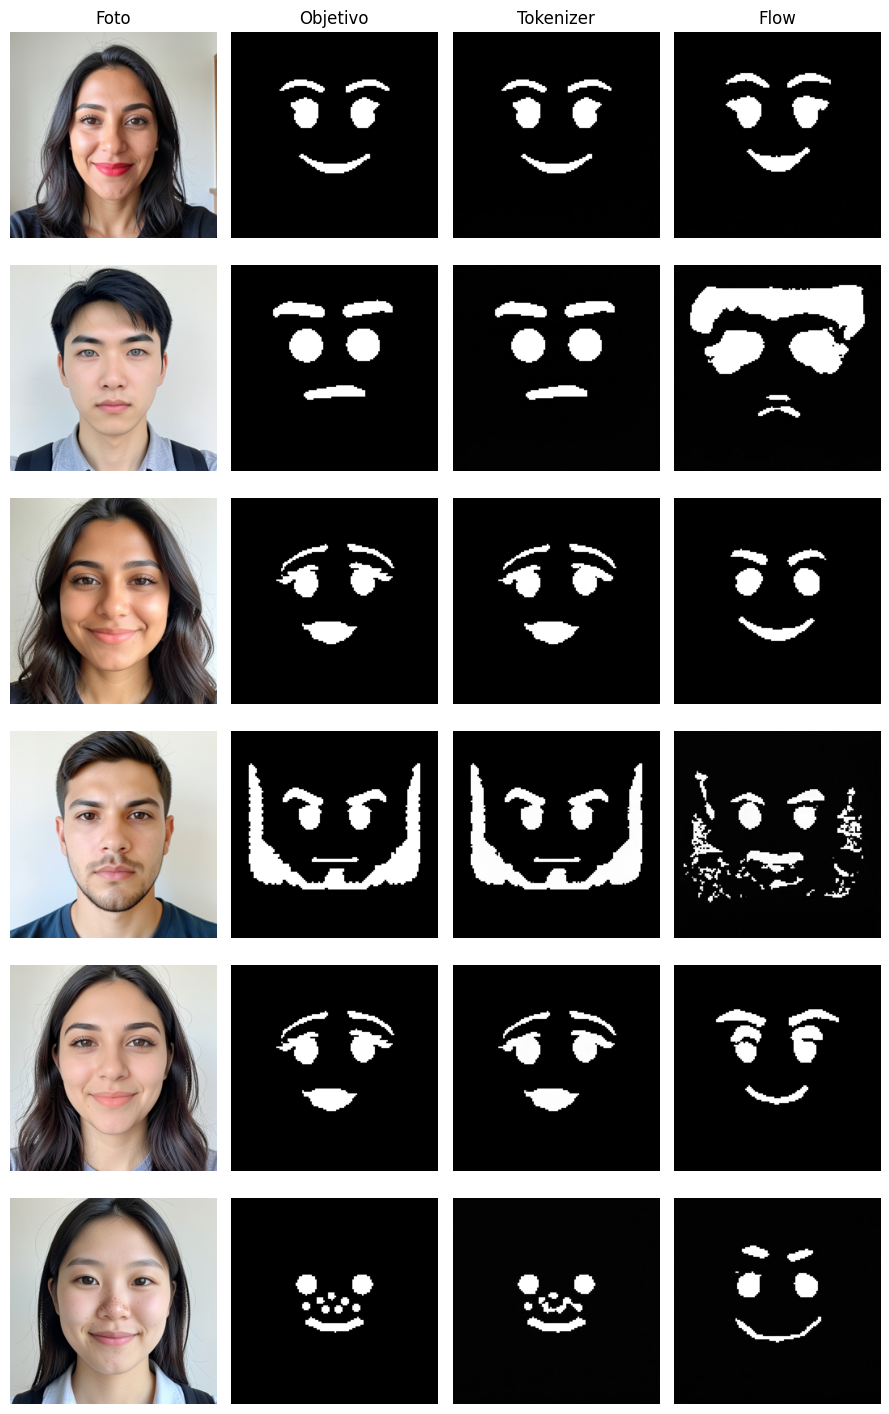

Salida: /kaggle/working/flow1_dito/f1d_dito_flow.zip


In [13]:
@torch.no_grad()
def mostrar(n=6,seed=42):
 rows=np.random.default_rng(seed).choice(TEST,min(n,len(TEST)),replace=False)
 fig,axes=plt.subplots(len(rows),4,figsize=(9,2.4*len(rows)),squeeze=False)
 for row,i in tqdm(list(enumerate(rows)),desc='Dibujando ejemplos',leave=False):
  mi=ROW_MASK[i];seeds=[seed+int(i)*1009]
  generated=decode_tokens(generate(MODELO,tokens_foto([i]),seeds,W),seeds,CONFIG['PASOS_DITO_FINAL'])[0,0].cpu()
  ceiling=decode_tokens(Z[mi:mi+1].to(DEVICE),seeds,CONFIG['PASOS_DITO_FINAL'])[0,0].cpu()
  images=[FOTOS[i].permute(1,2,0).numpy(),MASKS[mi,0],ceiling,generated]
  for a,img,title in zip(axes[row],images,['Foto','Objetivo','Tokenizer','Flow']):
   a.imshow(img,cmap='gray');a.axis('off')
   if row==0:a.set_title(title)
 plt.tight_layout();fig.savefig(RUN/'ejemplos_test.png',dpi=130);plt.show();plt.close(fig)
mostrar()

@torch.no_grad()
def inferir_foto(ruta,seed=42,w=None,pasos_flow=None,pasos_dito=None,mostrar=True):
 # Mismo recorte y normalización que en entrenamiento, sin aumentos.
 a,detected,_=crop_photo(pd.Series(dict(archivo=str(ruta),sha256_foto='')))
 x=torch.from_numpy(a.copy()).permute(2,0,1)[None].to(DINO_DEVICE).float()/255.
 x=F.interpolate(x,size=(CONFIG['LADO_FOTO'],)*2,mode='bilinear',align_corners=False,antialias=True)
 with amp_ctx():h=DINO(pixel_values=(x-IMNET_M)/IMNET_S).last_hidden_state
 z=generate(MODELO,h.float().to(DEVICE),[seed],W if w is None else w,pasos_flow)
 p=decode_tokens(z,[seed],pasos_dito or CONFIG['PASOS_DITO_FINAL'])[0,0].cpu().numpy()
 binary=(p>=.5).astype('uint8')*255
 if mostrar:
  fig,axes=plt.subplots(1,2,figsize=(6,3));axes[0].imshow(a);axes[0].set_title('Foto')
  axes[1].imshow(binary,cmap='gray',vmin=0,vmax=255);axes[1].set_title('Máscara generada')
  for ax in axes:ax.axis('off')
  plt.tight_layout();plt.show();plt.close(fig)
 return dict(mascara=binary,probabilidad=p,z=z.cpu(),cara_detectada=detected)
# ejemplo = inferir_foto('/kaggle/input/mis-fotos/foto.jpg')
export=dict(ema=MODELO.state_dict(),config=CONFIG,stats=dict(media=MEDIA,desv=DESV),
 dino=CONFIG['DINO'],processor=PROCESSOR_CONFIG,tokenizer_sha=TOKENIZER_SHA,signature=SIGNATURE_SHA,cfg_w=W,
 upstream=UPSTREAM_TEXT,nota='Necesita también el checkpoint DiTo base congelado; no contiene VAE antigua.')
torch.save(export,RUN/'flow1_dito.pt')
json.dump(dict(config=CONFIG,signature=SIGNATURE_SHA,dice_test_macro=macro_score(result),
 retrieval_macro=macro_score(retrieval_test),cfg_w=W,synthetic_only=True),open(RUN/'resumen.json','w'),indent=2)
# No incluir la copia de inputs ni el tokenizer ajeno: conservarlos por separado.
archive=shutil.make_archive(str(RUN),'zip',RUN.parent,RUN.name)
print('Salida:',archive)

## 13. Por qué esta versión y qué investigar después

[Esser et al., ICML 2024](https://proceedings.mlr.press/v235/esser24a.html) respalda el baseline rectified flow con muestreo temporal no uniforme. [DiTo, 2025](https://yinboc.github.io/dito/) aporta el codec reutilizado: se mantiene congelado para medir el mapeo foto→código. La normalización por canal del flow no es normalización de cada muestra a una esfera.

[CFG y memorización, CVPR 2025](https://ai.sony/publications/classifier-free-guidance-inside-the-attraction-basin-may-cause-memorization?hsLang=en) motiva evaluar copia y guidance por separado, sin afirmar que sea la causa de nuestros resultados. [REPA, ICLR 2025](https://github.com/sihyun-yu/REPA) alinea estados internos con features del target limpio: DINO como condición no es REPA. Un teacher de fotos humanas no es automáticamente adecuado para máscaras.

[CSFM, 2026](https://github.com/junwankimm/CSFM) aprende una fuente condicionada y usa control de varianza/alineamiento. Es una segunda ablación, no está implementado aquí ni se presenta este notebook como su reproducción. [Conditional OT, CoRL 2025](https://proceedings.mlr.press/v305/sochopoulos25a.html) advierte que acoplar ruido y targets ignorando condiciones puede sesgar generación. Se conserva el acoplamiento independiente correcto del baseline. [Memorización en RF, preprint 2026](https://arxiv.org/abs/2603.13421) estudia otra distribución temporal; no se extrapola su MIA a nuestro Dice.

Lectura del resultado: si el tokenizer reconstruye pero el flow no, comprobar señal fotográfica, regressor y retrieval. Si foto barajada casi no cambia la métrica, investigar condicionamiento. Si supera el oráculo de train y los rasgos son válidos, hay evidencia de adaptación útil que no explica una copia exacta. Ninguna de estas pruebas garantiza semántica o novedad por sí sola.

Verificación de entrega: sintaxis y esquema válidos; ejecución CPU completa con 12 máscaras/24 fotos artificiales y DINO de juguete; entrenamiento reducido, evaluación, exportación e inferencia externa; interrupción/reanudación de cuatro pasos con igualdad exacta de pesos frente a la corrida continua. Además, carga estricta de tu checkpoint real DiTo y una ejecución de su sampler, y prueba del lector real de CSV/parquet/PNG con 18 pares artificiales. Estas pruebas verifican conexiones y código, **no calidad de generación**.

El notebook no contiene resultados LEGO nuevos. La descarga de DINO preentrenado, CUDA/AMP, VRAM T4 y entrenamiento sobre tus inputs completos requieren ejecución en Kaggle. No se garantiza rendimiento por estar inspirado en literatura SOTA. El conjunto sintético de prueba local no se incorpora a tu dataset.